Processing P0781830301...
  Segment 1: category=low, bin_size=40s, total_counts=98
  Segment 2: category=low, bin_size=40s, total_counts=47
  Segment 3: category=medium, bin_size=20s, total_counts=575
  Segment 4: category=low, bin_size=40s, total_counts=241
  Segment 5: category=low, bin_size=40s, total_counts=136
Processing P0781830601...
  Segment 1: category=low, bin_size=40s, total_counts=150
  Segment 2: category=medium, bin_size=20s, total_counts=649
  Segment 3: category=low, bin_size=40s, total_counts=190
  Segment 4: category=low, bin_size=40s, total_counts=131
Processing P0801930701...
  Segment 1: category=low, bin_size=40s, total_counts=397
  Segment 2: category=medium, bin_size=20s, total_counts=439
  Segment 3: category=low, bin_size=40s, total_counts=46
  Segment 4: category=low, bin_size=40s, total_counts=93
  Segment 5: category=low, bin_size=40s, total_counts=101
  Segment 6: category=low, bin_size=40s, total_counts=90
  Segment 7: category=low, bin_size=40s, total_c

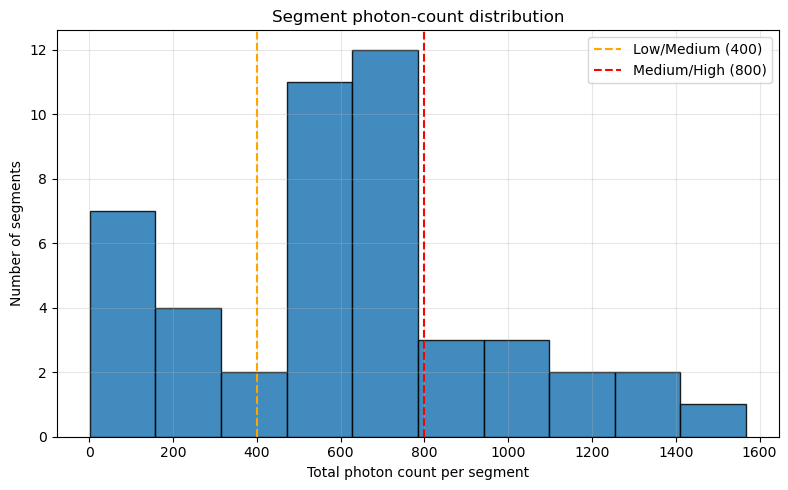

Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)
      0-200 |          7 |           0 |        0 |       1 |  0.000
    200-400 |          6 |           0 |        0 |       0 |  nan
    400-600 |         10 |           1 |        2 |       1 |  1.000
    600-800 |         14 |           1 |        3 |       0 |  nan
   800-1000 |          4 |           1 |        1 |       0 |  nan
  1000-1400 |          5 |           2 |        2 |       0 |  nan
  1400-2000 |          1 |           1 |        0 |       0 |  nan


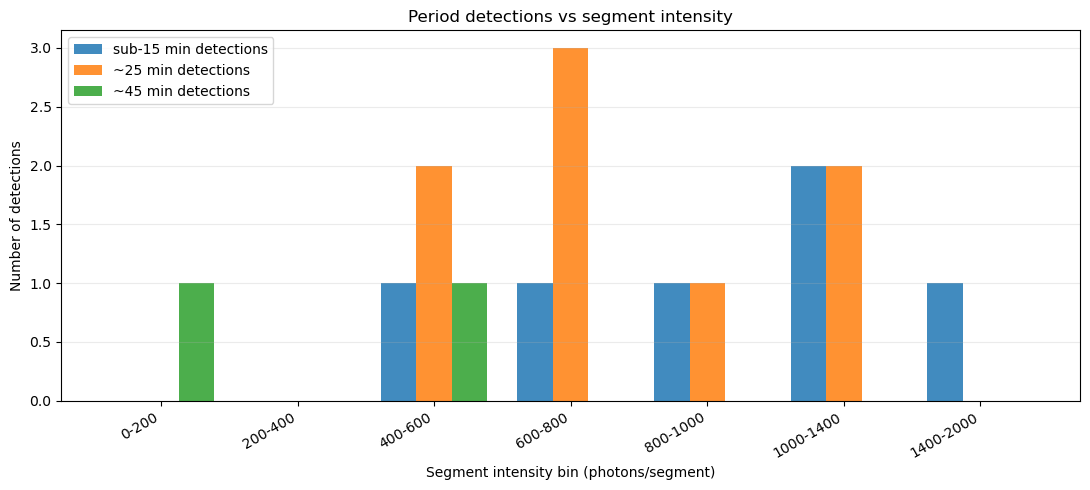

In [33]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Optional, Dict, Any, Tuple, List

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
tick_interval_h = 1
minor_interval_h = 1  # not used in this minimal LC+LS plot, kept for consistency

ident = ['P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
         'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
         'P0861950201', 'P0882110501', 'P0882110601']


base_bin_size = 10
data_dir = 'Data_Files/Fenn_Data/'


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 400, high_thresh: float = 800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category



for obs_id in ident:
    print(f"Processing {obs_id}...")
    times_dt, times_cxcsec = load_combined_times(obs_id, data_dir)
    gaps, gap_indices = find_gaps(times_cxcsec)

    # Define segments based on gaps
    segments = []
    start_idx = 0
    for idx in gap_indices:
        segments.append(times_cxcsec[start_idx:idx + 1])
        start_idx = idx + 1
    segments.append(times_cxcsec[start_idx:])  # last segment

    # Process each segment
    for i, segment in enumerate(segments):
        seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(segment, base_bin_size)
        print(f"  Segment {i+1}: category={category}, bin_size={seg_bin}s, total_counts={np.sum(hist_counts)}")

    if 'all_segment_counts' not in globals():
        all_segment_counts = []

    # one value per segment: total photon counts in that segment
    all_segment_counts.extend([int(len(seg)) for seg in segments])

    # plot once, after the last observation is processed
    if obs_id == ident[-1]:

        print(f"Total number of segments: {len(all_segment_counts)}")

        # Per-observation timeline plot: segments in blue, gaps in grey
        for obs_plot in ident:
            _, t_cxc = load_combined_times(obs_plot, data_dir)
            t_cxc = np.sort(t_cxc)

            gaps_plot, gap_idx_plot = find_gaps(t_cxc, threshold=3600.0)

            seg_bounds = []
            s = 0
            for gi in gap_idx_plot:
                seg_bounds.append((t_cxc[s], t_cxc[gi]))
                s = gi + 1
            seg_bounds.append((t_cxc[s], t_cxc[-1]))


            # Build a fresh per-run segment-count list (prevents accumulation across notebook reruns)
            if "_run_segment_counts" not in globals():
                _run_segment_counts = []

            seg_start_idx = np.r_[0, gap_idx_plot + 1]
            seg_end_idx = np.r_[gap_idx_plot + 1, len(t_cxc)]
            _run_segment_counts.extend((seg_end_idx - seg_start_idx).astype(int).tolist())

            # Finalize once at the end of the obs_plot loop
            if obs_plot == ident[-1]:
                all_segment_counts = _run_segment_counts.copy()
                del _run_segment_counts

                print(f"Corrected total number of segments (this run only): {len(all_segment_counts)}")

                # Histogram: total photon count per segment (this run only)
                plt.figure(figsize=(8, 5))

                plt.hist(all_segment_counts, bins=10, edgecolor='black', alpha=0.85)

                plt.xlabel('Total photon count per segment')
                plt.ylabel('Number of segments')
                plt.title('Segment photon-count distribution')
                plt.axvline(400, color='orange', linestyle='--', linewidth=1.5, label='Low/Medium (400)')
                plt.axvline(800, color='red', linestyle='--', linewidth=1.5, label='Medium/High (800)')
                plt.grid(alpha=0.3)
                plt.legend()
                plt.tight_layout()
                plt.show()

# --- User-defined settings ---
intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]  # photons/segment
gap_threshold_s = 3600.0

# Period windows (minutes)
sub15_window = (2.0, 15.0)       # "sub-15 min"
around25_window = (15.0, 35.0)   # "~25 min"
around45_window = (35.0, 55.0)   # "~45 min"

# Lomb-Scargle settings
search_period_range = (2.0, 90.0)  # min,max minutes to search globally
fap_alpha = 0.10                    # detection threshold (10% FAP)


def _split_segments_sorted(obs, gap_threshold=3600.0):
    _, t_cxc = load_combined_times(obs, data_dir)
    t_cxc = np.sort(t_cxc)
    _, gap_idx = find_gaps(t_cxc, threshold=gap_threshold)
    starts = np.r_[0, gap_idx + 1]
    ends = np.r_[gap_idx + 1, len(t_cxc)]
    return [t_cxc[s:e] for s, e in zip(starts, ends)]


def _detect_in_windows(segment_cxc):
    _seg_bin, centers, counts, _ = prepare_segment_bins(segment_cxc, base_bin_size)

    if len(centers) < 8 or np.sum(counts) <= 0:
        return False, False, False

    t_min = (centers - centers.min()) / 60.0
    y = counts.astype(float) - np.mean(counts)

    if np.allclose(y, 0):
        return False, False, False

    ls = LombScargle(t_min, y, fit_mean=False, center_data=True)
    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq, power = ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax, samples_per_peak=10)
    period_min = 1.0 / freq
    thresh = ls.false_alarm_level(fap_alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False
    return sub15_detect, p25_detect, p45_detect


# --- Build per-segment detection catalog across all observations ---
rows = []
for obs in ident:
    segs = _split_segments_sorted(obs, gap_threshold=gap_threshold_s)
    for seg in segs:
        sub15_det, p25_det, p45_det = _detect_in_windows(seg)
        rows.append((obs, len(seg), sub15_det, p25_det, p45_det))

rows = np.array(rows, dtype=object)
obs_arr = rows[:, 0]
nphot = rows[:, 1].astype(int)
sub15 = rows[:, 2].astype(bool)
p25 = rows[:, 3].astype(bool)
p45 = rows[:, 4].astype(bool)

# --- Bin by segment intensity ---
edges = np.asarray(intensity_bin_edges, dtype=float)
if np.any(np.diff(edges) <= 0):
    raise ValueError("intensity_bin_edges must be strictly increasing.")

bin_idx = np.digitize(nphot, edges, right=False) - 1
valid = (bin_idx >= 0) & (bin_idx < len(edges) - 1)

labels, n_seg, n_sub, n_25, n_45, ratio, ratio_err = [], [], [], [], [], [], []
for i_bin in range(len(edges) - 1):
    m = valid & (bin_idx == i_bin)
    ns = int(np.sum(m))
    s = int(np.sum(sub15[m]))
    p = int(np.sum(p25[m]))
    q = int(np.sum(p45[m]))

    labels.append(f"{int(edges[i_bin])}-{int(edges[i_bin+1])}")
    n_seg.append(ns)
    n_sub.append(s)
    n_25.append(p)
    n_45.append(q)

    if q > 0:
        r = s / q
        re = r * np.sqrt((1 / s if s > 0 else 0) + (1 / q))
    else:
        r = np.nan
        re = np.nan

    ratio.append(r)
    ratio_err.append(re)

# --- Print summary table ---
print("Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)")
for a, b, c, p, d, e in zip(labels, n_seg, n_sub, n_25, n_45, ratio):
    print(f"{a:>11} | {b:10d} | {c:11d} | {p:8d} | {d:7d} | {e: .3f}")

# --- Plot ---
x = np.arange(len(labels))

fig, ax1 = plt.subplots(figsize=(11, 5))
w = 0.26
ax1.bar(x - w, n_sub, width=w, label="sub-15 min detections", alpha=0.85)
ax1.bar(x, n_25, width=w, label="~25 min detections", alpha=0.85)
ax1.bar(x + w, n_45, width=w, label="~45 min detections", alpha=0.85)
ax1.set_ylabel("Number of detections")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=30, ha="right")
ax1.set_xlabel("Segment intensity bin (photons/segment)")
ax1.grid(alpha=0.25, axis="y")
ax1.legend(loc="upper left")

plt.title("Period detections vs segment intensity")
plt.tight_layout()
plt.show()

Processing P0781830301 (raw_unbinned) ... 2 segments
Processing P0781830601 (raw_unbinned) ... 2 segments
Processing P0801930701 (raw_unbinned) ... 4 segments
Processing P0801930801 (raw_unbinned) ... 5 segments
Processing P0801930901 (raw_unbinned) ... 3 segments
Processing P0801931901 (raw_unbinned) ... 3 segments
Processing P0842810501 (raw_unbinned) ... 4 segments
Processing P0842811001 (raw_unbinned) ... 4 segments
Processing P0842811501 (raw_unbinned) ... 4 segments
Processing P0842812001 (raw_unbinned) ... 4 segments
Processing P0861950201 (raw_unbinned) ... 4 segments
Processing P0882110501 (raw_unbinned) ... 3 segments
Processing P0882110601 (raw_unbinned) ... 5 segments

=== raw_unbinned ===
Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)
      0-200 |          7 |           1 |        1 |       1 |  1.000
    200-400 |          6 |           1 |        3 |       2 |  0.500
    400-600 |         10 |           3 |        4 |       3 |  1.000


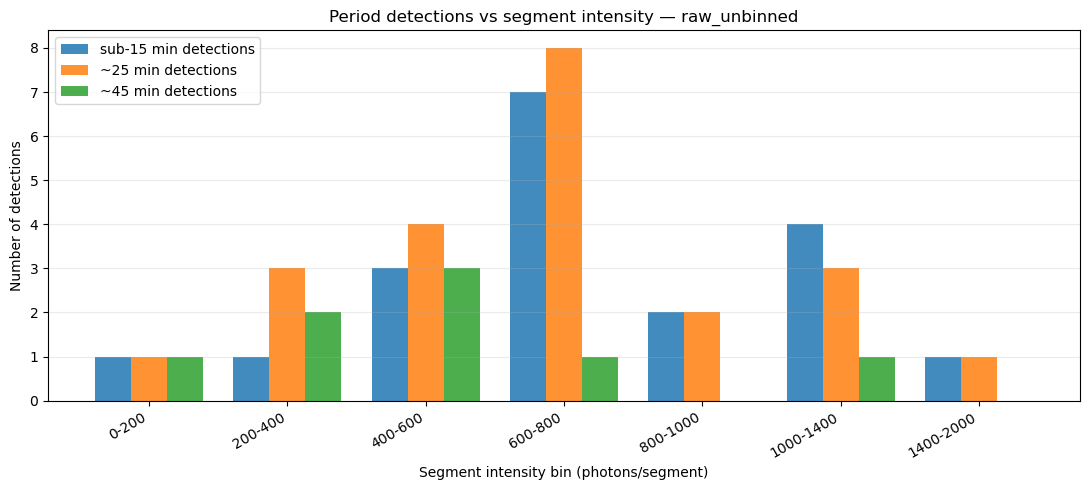

Processing P0781830301 (fixed_60s) ... 2 segments
Processing P0781830601 (fixed_60s) ... 2 segments
Processing P0801930701 (fixed_60s) ... 4 segments
Processing P0801930801 (fixed_60s) ... 5 segments
Processing P0801930901 (fixed_60s) ... 3 segments
Processing P0801931901 (fixed_60s) ... 3 segments
Processing P0842810501 (fixed_60s) ... 4 segments
Processing P0842811001 (fixed_60s) ... 4 segments
Processing P0842811501 (fixed_60s) ... 4 segments
Processing P0842812001 (fixed_60s) ... 4 segments
Processing P0861950201 (fixed_60s) ... 4 segments
Processing P0882110501 (fixed_60s) ... 3 segments
Processing P0882110601 (fixed_60s) ... 5 segments

=== fixed_60s ===
Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)
      0-200 |          7 |           1 |        0 |       0 |  nan
    200-400 |          6 |           0 |        0 |       0 |  nan
    400-600 |         10 |           0 |        1 |       1 |  0.000
    600-800 |         14 |           0 |      

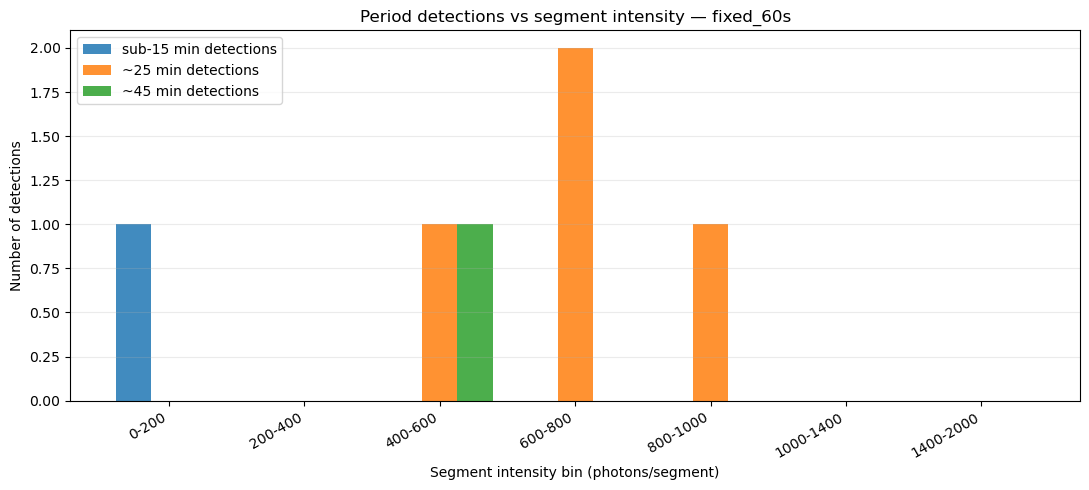

Processing P0781830301 (dynamic) ... 2 segments
Processing P0781830601 (dynamic) ... 2 segments
Processing P0801930701 (dynamic) ... 4 segments
Processing P0801930801 (dynamic) ... 5 segments
Processing P0801930901 (dynamic) ... 3 segments
Processing P0801931901 (dynamic) ... 3 segments
Processing P0842810501 (dynamic) ... 4 segments
Processing P0842811001 (dynamic) ... 4 segments
Processing P0842811501 (dynamic) ... 4 segments
Processing P0842812001 (dynamic) ... 4 segments
Processing P0861950201 (dynamic) ... 4 segments
Processing P0882110501 (dynamic) ... 3 segments
Processing P0882110601 (dynamic) ... 5 segments

=== dynamic ===
Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)
      0-200 |          7 |           0 |        0 |       1 |  0.000
    200-400 |          6 |           0 |        0 |       0 |  nan
    400-600 |         10 |           1 |        2 |       1 |  1.000
    600-800 |         14 |           1 |        3 |       0 |  nan
   80

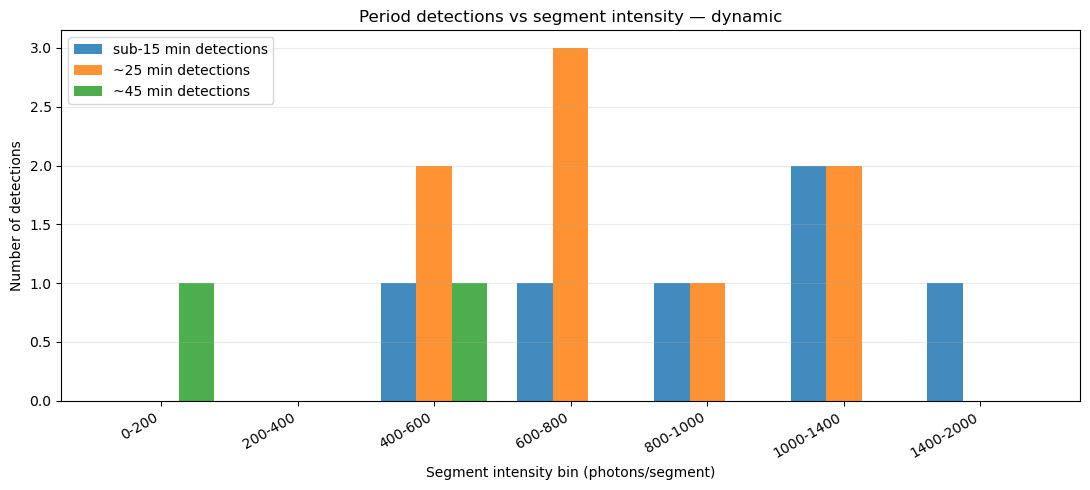

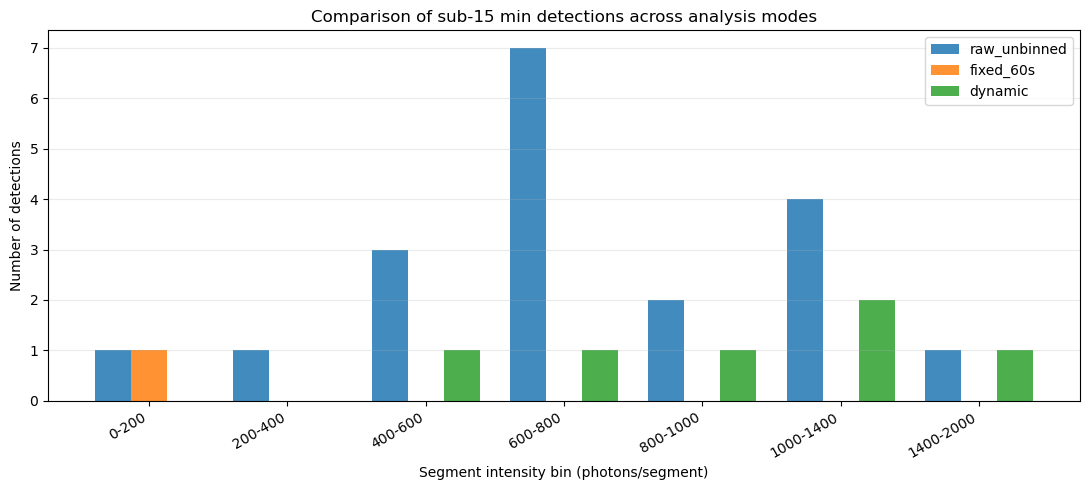

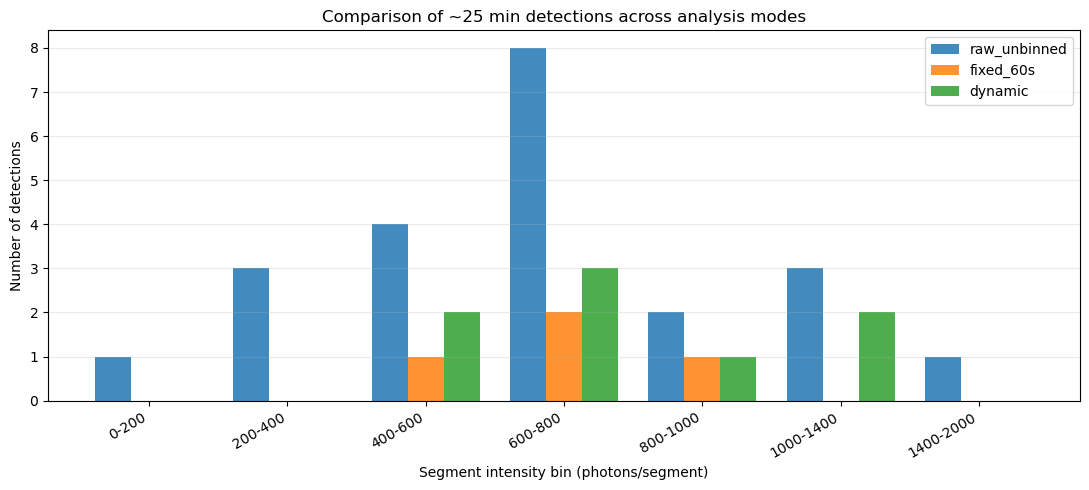

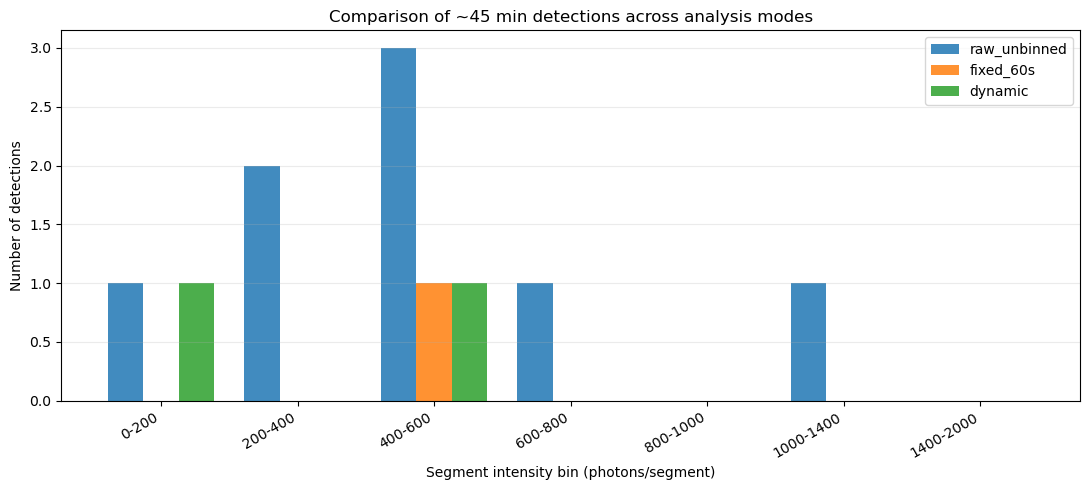

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Dict, Tuple, List
from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = [
    'P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
    'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
    'P0861950201', 'P0882110501', 'P0882110601'
]

data_dir = 'Data_Files/Fenn_Data/'
base_bin_size = 10                # used for segment categorisation
fixed_bin_size_s = 60.0           # second run
gap_threshold_s = 3600.0

# intensity bins for the summary plots
intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]

# Period windows (minutes)
sub15_window = (2.0, 15.0)
around25_window = (15.0, 35.0)
around45_window = (35.0, 55.0)

# global search range (minutes)
search_period_range = (2.0, 90.0)

# significance threshold
fap_alpha = 0.10


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def _split_segments_sorted(obs: str, gap_threshold: float = 3600.0):
    """
    Return list of time-sorted photon-arrival segments for one observation.
    """
    _, t_cxc = load_combined_times(obs, data_dir)
    t_cxc = np.sort(t_cxc)

    _, gap_idx = find_gaps(t_cxc, threshold=gap_threshold)
    starts = np.r_[0, gap_idx + 1]
    ends = np.r_[gap_idx + 1, len(t_cxc)]

    return [t_cxc[s:e] for s, e in zip(starts, ends)]


# ─── BINNING HELPERS ──────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 400, high_thresh: float = 800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── PERIOD SEARCH HELPERS ────────────────────────────────────────────────────
def rayleigh_power(phases_rad: np.ndarray) -> float:
    """
    Classical Z1^2 / N Rayleigh power for one trial frequency.
    """
    n = len(phases_rad)
    if n == 0:
        return np.nan
    csum = np.sum(np.cos(phases_rad))
    ssum = np.sum(np.sin(phases_rad))
    return (csum**2 + ssum**2) / n


def detect_periods_unbinned_rayleigh(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
    nfreq=5000,
):
    """
    Unbinned search using a Rayleigh test on event arrival times.
    """
    if len(event_times_cxc) < 8:
        return False, False, False

    t_min = (event_times_cxc - np.min(event_times_cxc)) / 60.0
    duration_min = np.max(t_min) - np.min(t_min)

    if duration_min <= 0:
        return False, False, False

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)
    period_min = 1.0 / freq

    power = np.empty_like(freq)
    for i, f in enumerate(freq):
        phases = 2.0 * np.pi * f * t_min
        power[i] = rayleigh_power(phases)

    # approximate multi-trial threshold for Rayleigh
    # single-trial tail ~ exp(-z), so global FAP ~ M exp(-z)
    # => z ~ ln(M/alpha)
    m_trials = len(freq)
    thresh = np.log(m_trials / alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect


def detect_periods_binned_ls(
    centers: np.ndarray,
    counts: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
):
    """
    Binned count-rate Lomb–Scargle search.
    """
    if len(centers) < 8 or np.sum(counts) <= 0:
        return False, False, False

    t_min = (centers - centers.min()) / 60.0
    y = counts.astype(float) - np.mean(counts)

    if np.allclose(y, 0):
        return False, False, False

    ls = LombScargle(t_min, y, fit_mean=False, center_data=True)
    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq, power = ls.autopower(
        minimum_frequency=fmin,
        maximum_frequency=fmax,
        samples_per_peak=10
    )
    period_min = 1.0 / freq
    thresh = ls.false_alarm_level(alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect


def detect_segment(segment_cxc: np.ndarray, mode: str):
    """
    mode:
      - 'raw_unbinned'
      - 'fixed_60s'
      - 'dynamic'
    """
    if mode == 'raw_unbinned':
        return detect_periods_unbinned_rayleigh(
            segment_cxc,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    elif mode == 'fixed_60s':
        centers, counts = bin_photon_times(segment_cxc, fixed_bin_size_s)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    elif mode == 'dynamic':
        _, centers, counts, _ = prepare_segment_bins(segment_cxc, base_bin_size)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    else:
        raise ValueError("mode must be 'raw_unbinned', 'fixed_60s', or 'dynamic'")


# ─── RUN ONE MODE ─────────────────────────────────────────────────────────────
def run_detection_mode(mode: str, intensity_bin_edges: List[float]):
    """
    Build per-segment detection catalog and summary for one mode.
    """
    rows = []

    for obs in ident:
        segs = _split_segments_sorted(obs, gap_threshold=gap_threshold_s)
        print(f"Processing {obs} ({mode}) ... {len(segs)} segments")

        for i, seg in enumerate(segs, start=1):
            sub15_det, p25_det, p45_det = detect_segment(seg, mode)
            rows.append((obs, len(seg), sub15_det, p25_det, p45_det))

    rows = np.array(rows, dtype=object)
    obs_arr = rows[:, 0]
    nphot = rows[:, 1].astype(int)
    sub15 = rows[:, 2].astype(bool)
    p25 = rows[:, 3].astype(bool)
    p45 = rows[:, 4].astype(bool)

    edges = np.asarray(intensity_bin_edges, dtype=float)
    if np.any(np.diff(edges) <= 0):
        raise ValueError("intensity_bin_edges must be strictly increasing.")

    bin_idx = np.digitize(nphot, edges, right=False) - 1
    valid = (bin_idx >= 0) & (bin_idx < len(edges) - 1)

    labels, n_seg, n_sub, n_25, n_45, ratio, ratio_err = [], [], [], [], [], [], []

    for i_bin in range(len(edges) - 1):
        m = valid & (bin_idx == i_bin)

        ns = int(np.sum(m))
        s = int(np.sum(sub15[m]))
        p = int(np.sum(p25[m]))
        q = int(np.sum(p45[m]))

        labels.append(f"{int(edges[i_bin])}-{int(edges[i_bin+1])}")
        n_seg.append(ns)
        n_sub.append(s)
        n_25.append(p)
        n_45.append(q)

        if q > 0:
            r = s / q
            re = r * np.sqrt((1 / s if s > 0 else 0) + (1 / q))
        else:
            r = np.nan
            re = np.nan

        ratio.append(r)
        ratio_err.append(re)

    summary = {
        "mode": mode,
        "labels": labels,
        "n_seg": np.array(n_seg),
        "n_sub": np.array(n_sub),
        "n_25": np.array(n_25),
        "n_45": np.array(n_45),
        "ratio": np.array(ratio, dtype=float),
        "ratio_err": np.array(ratio_err, dtype=float),
        "rows": rows,
    }
    return summary


def print_summary_table(summary: Dict):
    print(f"\n=== {summary['mode']} ===")
    print("Intensity bin | N segments | sub<15m det | ~25m det | ~45m det | ratio(sub15/~45)")
    for a, b, c, p, d, e in zip(
        summary["labels"],
        summary["n_seg"],
        summary["n_sub"],
        summary["n_25"],
        summary["n_45"],
        summary["ratio"],
    ):
        print(f"{a:>11} | {b:10d} | {c:11d} | {p:8d} | {d:7d} | {e: .3f}")


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_single_mode(summary: Dict):
    x = np.arange(len(summary["labels"]))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, summary["n_sub"], width=w, label="sub-15 min detections", alpha=0.85)
    ax.bar(x,      summary["n_25"], width=w, label="~25 min detections", alpha=0.85)
    ax.bar(x + w,  summary["n_45"], width=w, label="~45 min detections", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend(loc="upper left")
    ax.set_title(f"Period detections vs segment intensity — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_mode_comparison(results: Dict[str, Dict], family: str = "sub15"):
    """
    family: 'sub15', 'p25', 'p45'
    """
    key_map = {
        "sub15": "n_sub",
        "p25": "n_25",
        "p45": "n_45",
    }
    title_map = {
        "sub15": "sub-15 min detections",
        "p25": "~25 min detections",
        "p45": "~45 min detections",
    }

    key = key_map[family]
    labels = results["raw_unbinned"]["labels"]
    x = np.arange(len(labels))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, results["raw_unbinned"][key], width=w, label="raw_unbinned", alpha=0.85)
    ax.bar(x,      results["fixed_60s"][key],   width=w, label="fixed_60s", alpha=0.85)
    ax.bar(x + w,  results["dynamic"][key],     width=w, label="dynamic", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend()
    ax.set_title(f"Comparison of {title_map[family]} across analysis modes")

    plt.tight_layout()
    plt.show()


# ─── MAIN RUN ─────────────────────────────────────────────────────────────────
modes = ["raw_unbinned", "fixed_60s", "dynamic"]
results = {}

for mode in modes:
    results[mode] = run_detection_mode(mode, intensity_bin_edges)
    print_summary_table(results[mode])
    plot_single_mode(results[mode])

# Comparison plots
plot_mode_comparison(results, family="sub15")
plot_mode_comparison(results, family="p25")
plot_mode_comparison(results, family="p45")

Processing P0781830301 (raw_unbinned) ... 2 segments
Processing P0781830601 (raw_unbinned) ... 2 segments
Processing P0801930701 (raw_unbinned) ... 4 segments
Processing P0801930801 (raw_unbinned) ... 5 segments
Processing P0801930901 (raw_unbinned) ... 3 segments
Processing P0801931901 (raw_unbinned) ... 3 segments
Processing P0842810501 (raw_unbinned) ... 4 segments
Processing P0842811001 (raw_unbinned) ... 4 segments
Processing P0842811501 (raw_unbinned) ... 4 segments
Processing P0842812001 (raw_unbinned) ... 4 segments
Processing P0861950201 (raw_unbinned) ... 4 segments
Processing P0882110501 (raw_unbinned) ... 3 segments
Processing P0882110601 (raw_unbinned) ... 5 segments

=== raw_unbinned ===
Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)
      0-200 |     7 |          1 |       1 |       1 |      0.143 |    0.143 |    0.143 |          1.000
    200-400 |     6 |          1 |       3 |       2 |      0.167 |    0.5

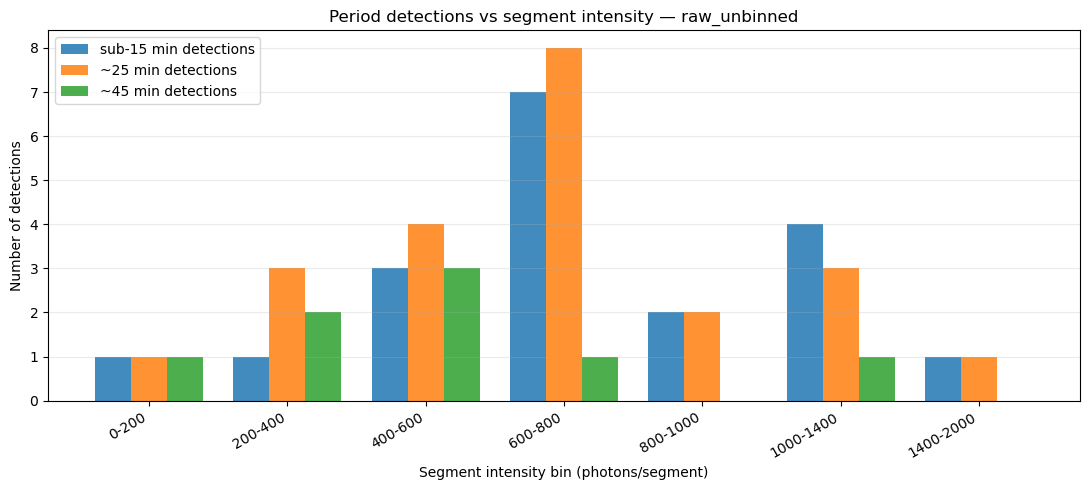

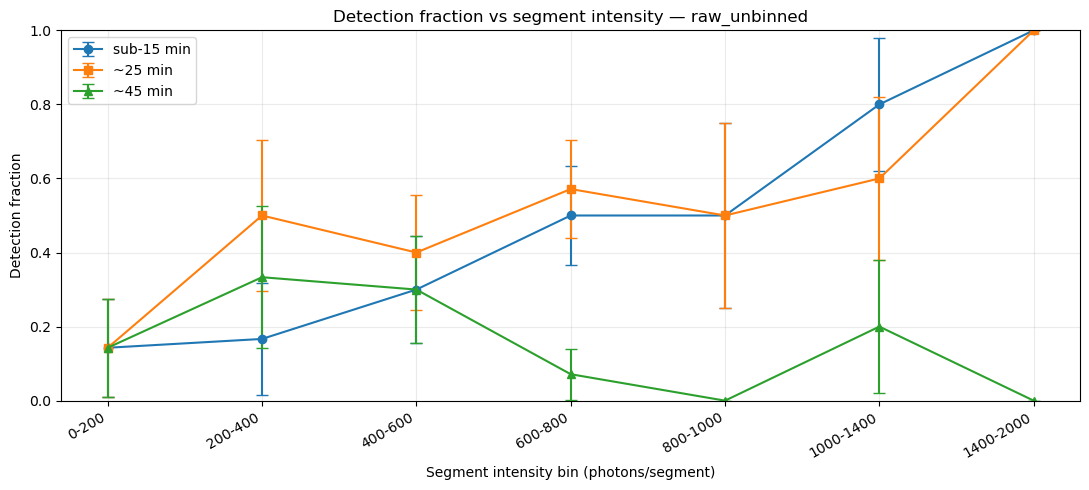

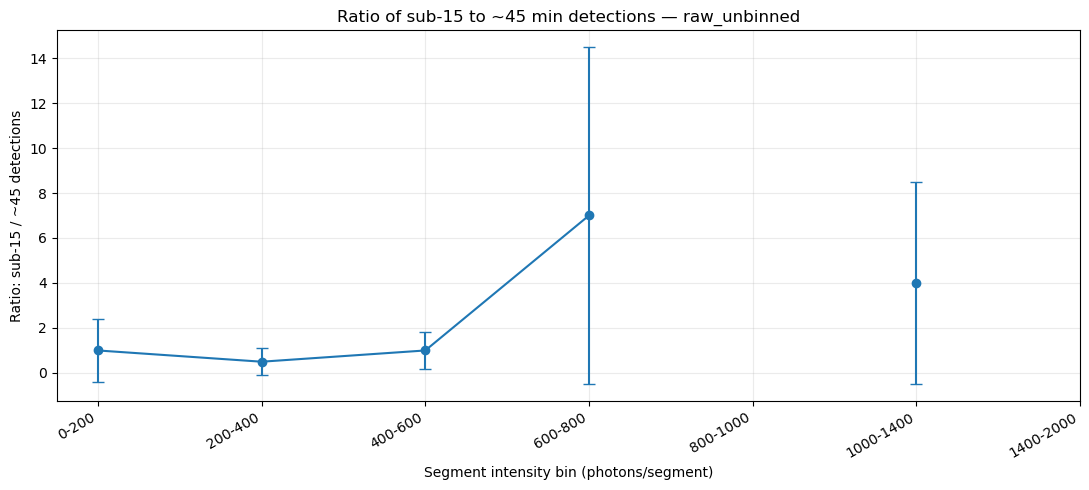

Processing P0781830301 (fixed_60s) ... 2 segments
Processing P0781830601 (fixed_60s) ... 2 segments
Processing P0801930701 (fixed_60s) ... 4 segments
Processing P0801930801 (fixed_60s) ... 5 segments
Processing P0801930901 (fixed_60s) ... 3 segments
Processing P0801931901 (fixed_60s) ... 3 segments
Processing P0842810501 (fixed_60s) ... 4 segments
Processing P0842811001 (fixed_60s) ... 4 segments
Processing P0842811501 (fixed_60s) ... 4 segments
Processing P0842812001 (fixed_60s) ... 4 segments
Processing P0861950201 (fixed_60s) ... 4 segments
Processing P0882110501 (fixed_60s) ... 3 segments
Processing P0882110601 (fixed_60s) ... 5 segments

=== fixed_60s ===
Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)
      0-200 |     7 |          1 |       0 |       0 |      0.143 |    0.000 |    0.000 |            nan
    200-400 |     6 |          0 |       0 |       0 |      0.000 |    0.000 |    0.000 |            nan
    400-600

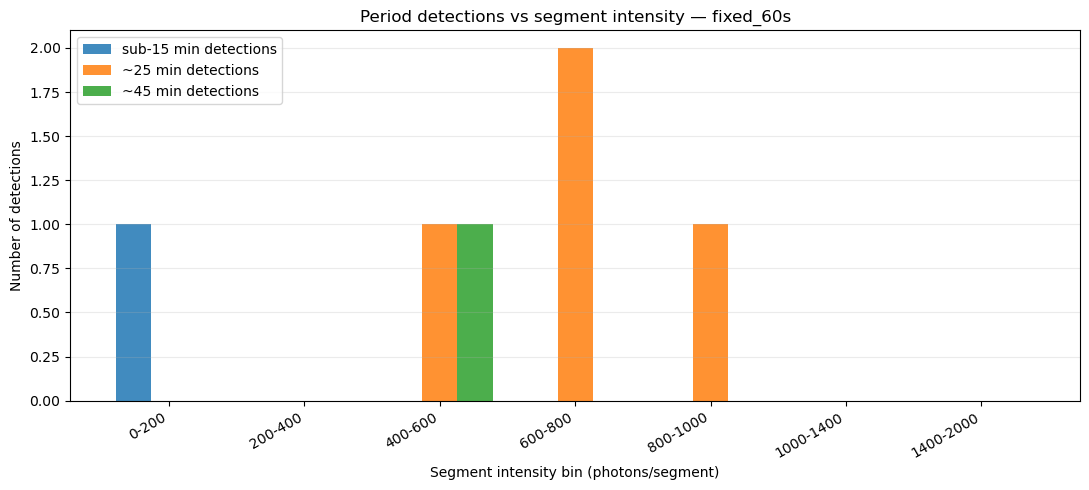

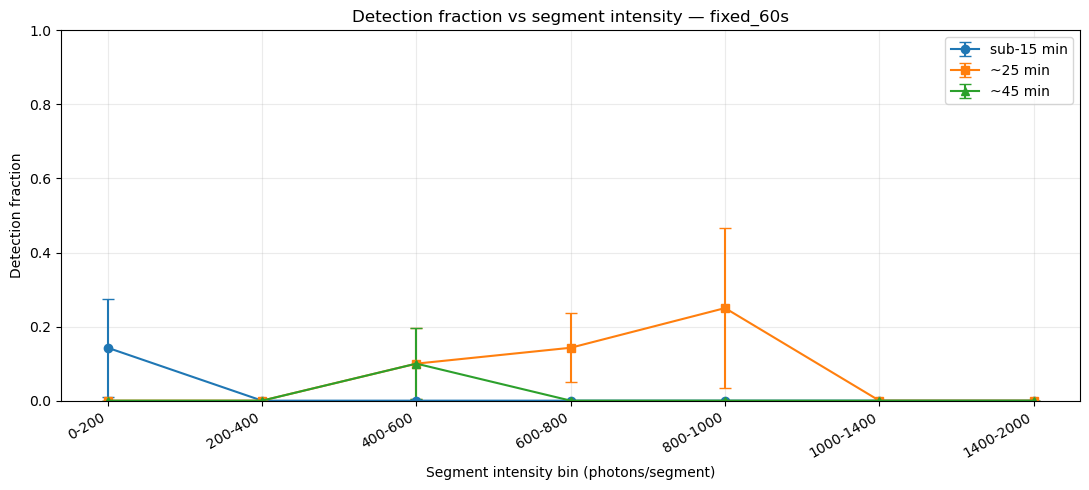

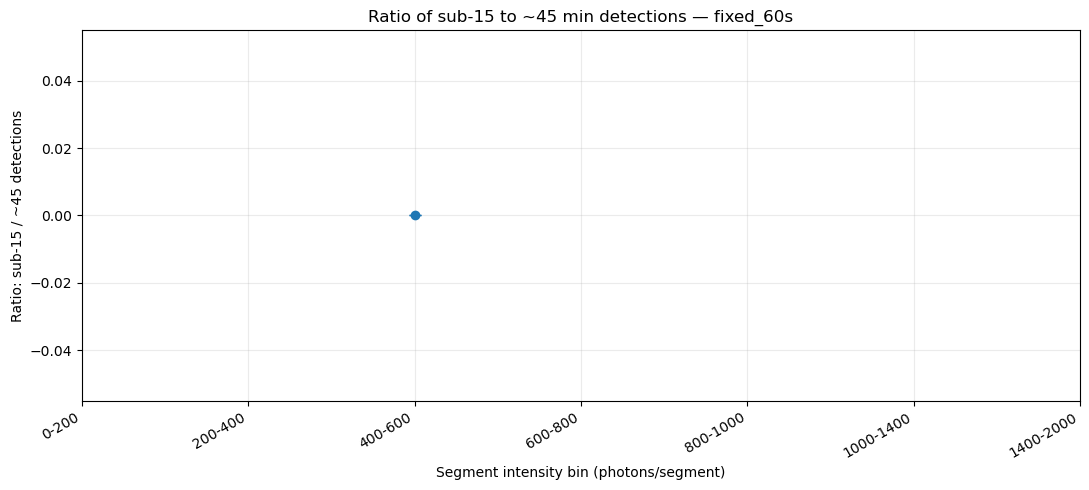

Processing P0781830301 (dynamic) ... 2 segments
Processing P0781830601 (dynamic) ... 2 segments
Processing P0801930701 (dynamic) ... 4 segments
Processing P0801930801 (dynamic) ... 5 segments
Processing P0801930901 (dynamic) ... 3 segments
Processing P0801931901 (dynamic) ... 3 segments
Processing P0842810501 (dynamic) ... 4 segments
Processing P0842811001 (dynamic) ... 4 segments
Processing P0842811501 (dynamic) ... 4 segments
Processing P0842812001 (dynamic) ... 4 segments
Processing P0861950201 (dynamic) ... 4 segments
Processing P0882110501 (dynamic) ... 3 segments
Processing P0882110601 (dynamic) ... 5 segments

=== dynamic ===
Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)
      0-200 |     7 |          0 |       0 |       1 |      0.000 |    0.000 |    0.143 |          0.000
    200-400 |     6 |          0 |       0 |       0 |      0.000 |    0.000 |    0.000 |            nan
    400-600 |    10 |          1 |     

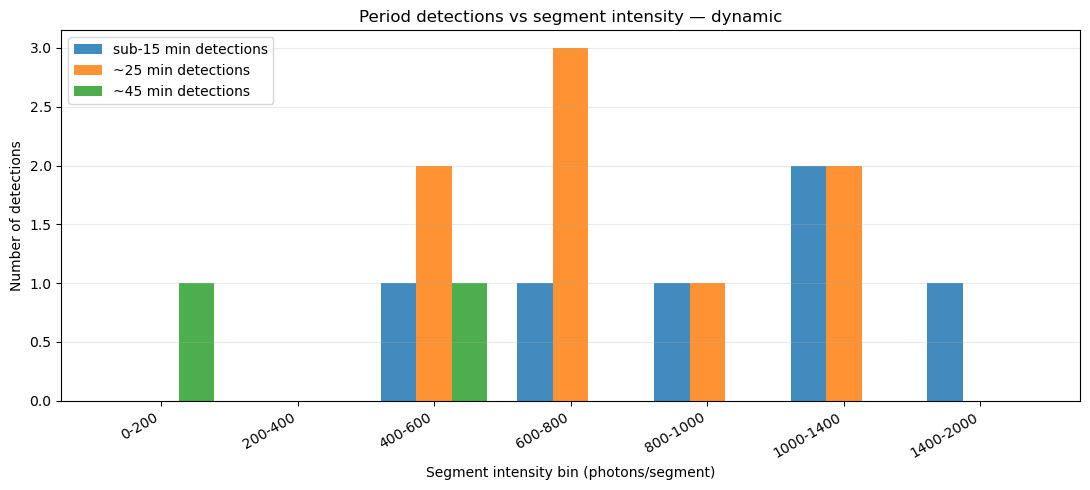

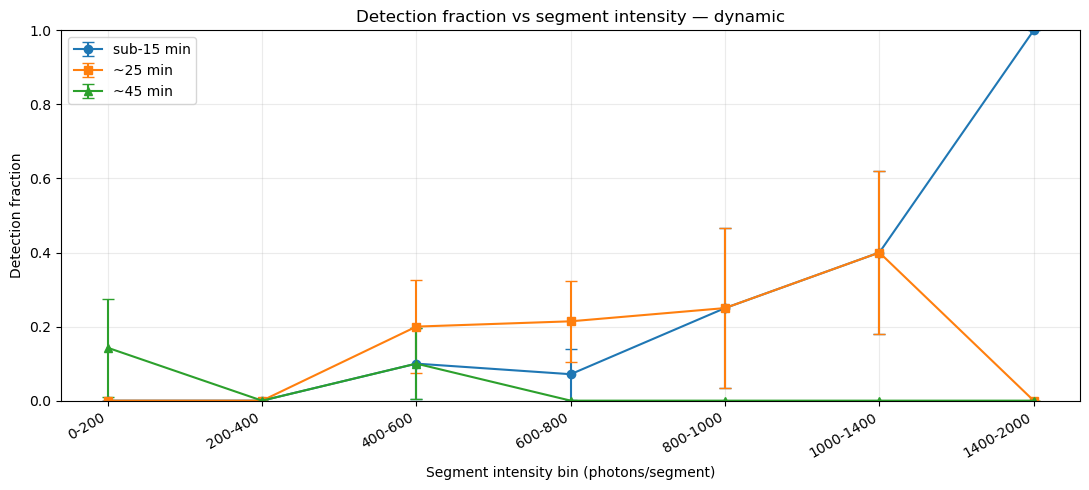

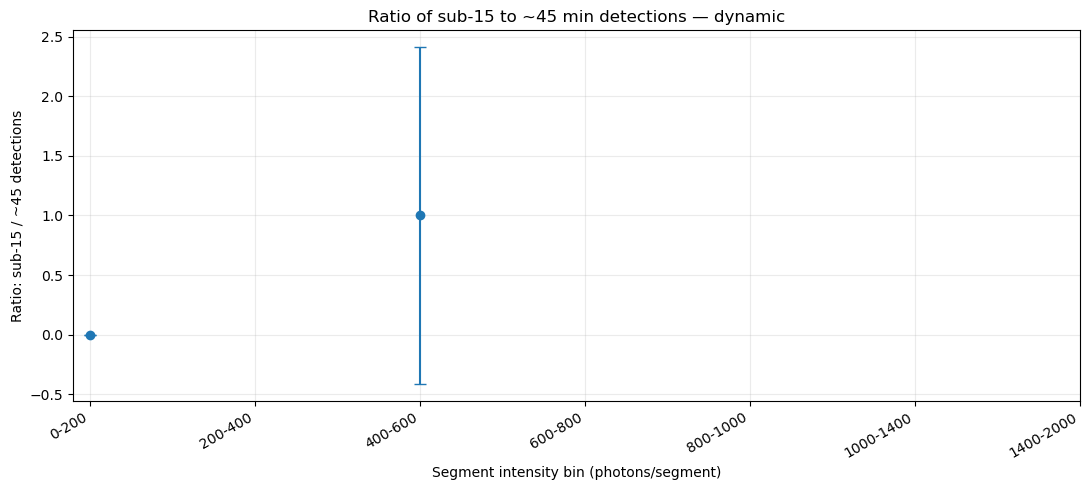

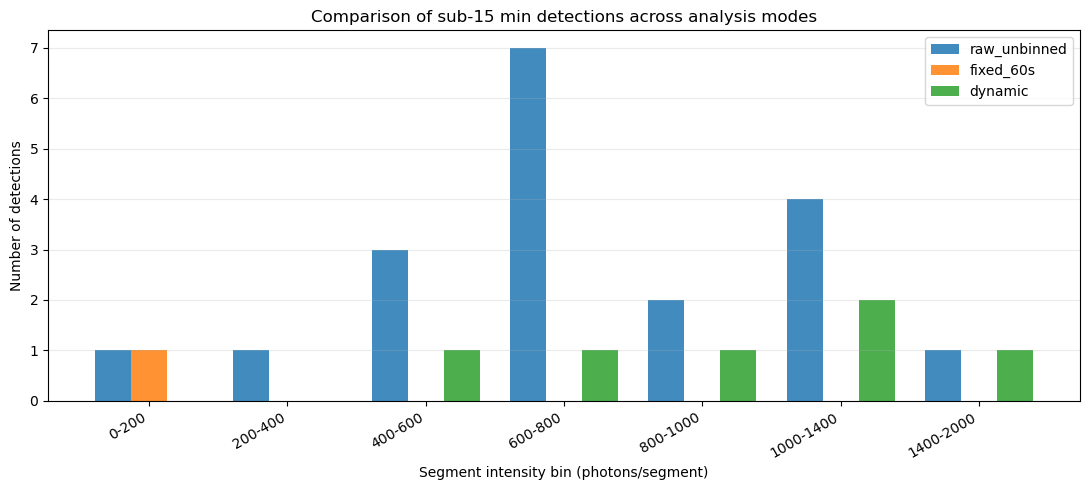

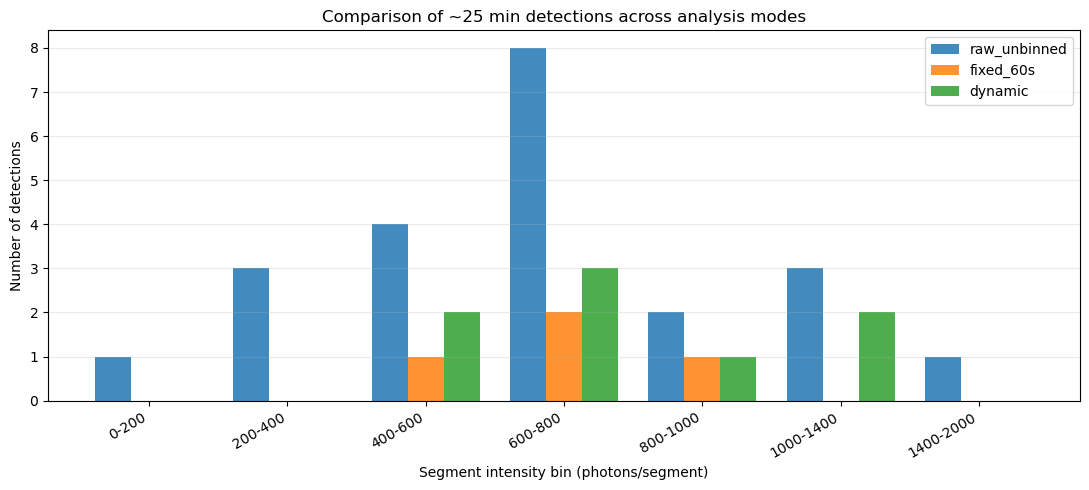

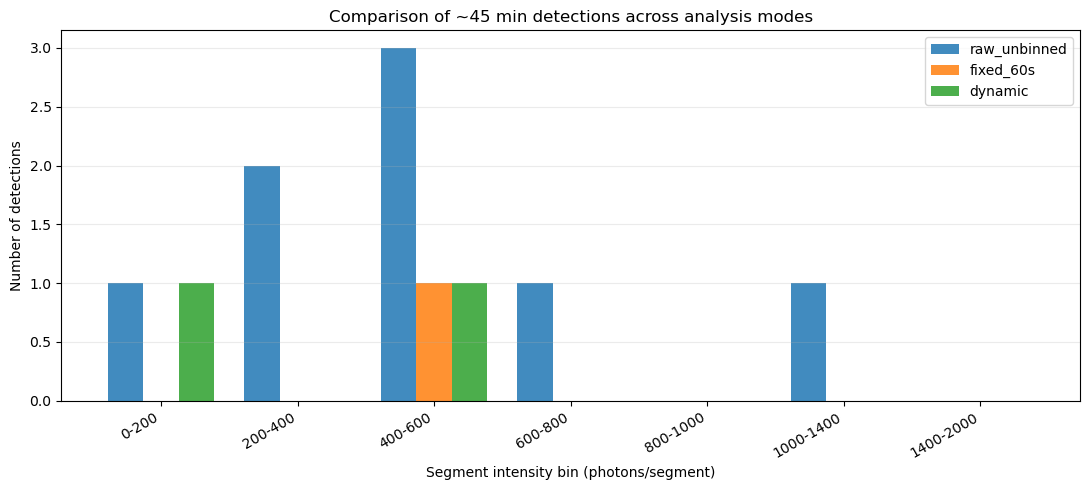

AttributeError: Line2D.set() got an unexpected keyword argument 'capsize'

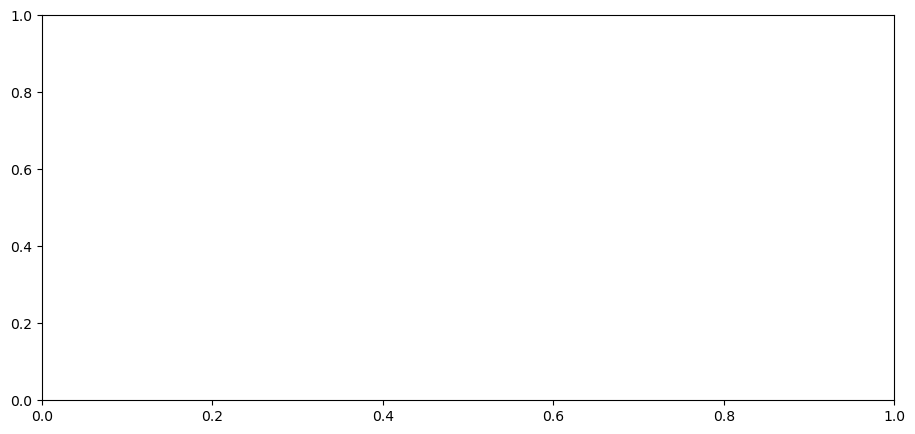

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Dict, List
from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = [
    'P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
    'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
    'P0861950201', 'P0882110501', 'P0882110601'
]

data_dir = 'Data_Files/Fenn_Data/'

# gap threshold for defining segments
gap_threshold_s = 3600.0

# fixed bin size for the second run
fixed_bin_size_s = 60.0

# used for your dynamic-binning logic
base_bin_size = 10

# intensity bins for total photons per segment
intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]

# Period windows (minutes)
sub15_window = (2.0, 15.0)
around25_window = (15.0, 35.0)
around45_window = (35.0, 55.0)

# global search range (minutes)
search_period_range = (2.0, 90.0)

# significance threshold
fap_alpha = 0.10


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def split_segments_sorted(obs_id: str, gap_threshold: float = 3600.0):
    """
    Return a list of sorted photon-arrival-time segments for one observation.
    """
    _, t_cxc = load_combined_times(obs_id, data_dir)
    t_cxc = np.sort(t_cxc)

    _, gap_idx = find_gaps(t_cxc, threshold=gap_threshold)
    starts = np.r_[0, gap_idx + 1]
    ends = np.r_[gap_idx + 1, len(t_cxc)]

    return [t_cxc[s:e] for s, e in zip(starts, ends)]


# ─── BINNING HELPERS ──────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon times (CXC seconds) into uniform bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))

    bins = np.arange(start, end + bin_size, bin_size)
    if len(bins) < 2:
        bins = np.array([start, start + bin_size])

    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 400, high_thresh: float = 800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── PERIOD SEARCH HELPERS ────────────────────────────────────────────────────
def rayleigh_power(phases_rad: np.ndarray) -> float:
    """
    Classical Rayleigh Z1^2 / N power for one trial frequency.
    """
    n = len(phases_rad)
    if n == 0:
        return np.nan
    csum = np.sum(np.cos(phases_rad))
    ssum = np.sum(np.sin(phases_rad))
    return (csum**2 + ssum**2) / n


def detect_periods_unbinned_rayleigh(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
    nfreq=5000,
):
    """
    Unbinned search using a Rayleigh test on event arrival times.
    """
    if len(event_times_cxc) < 8:
        return False, False, False

    t_min = (event_times_cxc - np.min(event_times_cxc)) / 60.0
    duration_min = np.max(t_min) - np.min(t_min)
    if duration_min <= 0:
        return False, False, False

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)
    period_min = 1.0 / freq

    power = np.empty_like(freq)
    for i, f in enumerate(freq):
        phases = 2.0 * np.pi * f * t_min
        power[i] = rayleigh_power(phases)

    # Approximate multi-trial Rayleigh threshold:
    # global FAP ~ M exp(-z)  => z ~ ln(M/alpha)
    m_trials = len(freq)
    thresh = np.log(m_trials / alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect


def detect_periods_binned_ls(
    centers: np.ndarray,
    counts: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
):
    """
    Binned count-rate Lomb–Scargle search.
    """
    if len(centers) < 8 or np.sum(counts) <= 0:
        return False, False, False

    t_min = (centers - centers.min()) / 60.0
    y = counts.astype(float) - np.mean(counts)

    if np.allclose(y, 0):
        return False, False, False

    ls = LombScargle(t_min, y, fit_mean=False, center_data=True)
    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]

    freq, power = ls.autopower(
        minimum_frequency=fmin,
        maximum_frequency=fmax,
        samples_per_peak=10,
    )
    period_min = 1.0 / freq
    thresh = ls.false_alarm_level(alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect


def detect_segment(segment_cxc: np.ndarray, mode: str):
    """
    mode:
      - 'raw_unbinned'
      - 'fixed_60s'
      - 'dynamic'
    """
    if mode == 'raw_unbinned':
        return detect_periods_unbinned_rayleigh(
            segment_cxc,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    elif mode == 'fixed_60s':
        centers, counts = bin_photon_times(segment_cxc, fixed_bin_size_s)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    elif mode == 'dynamic':
        _, centers, counts, _ = prepare_segment_bins(segment_cxc, base_bin_size)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    else:
        raise ValueError("mode must be 'raw_unbinned', 'fixed_60s', or 'dynamic'")


# ─── ANALYSIS ─────────────────────────────────────────────────────────────────
def run_detection_mode(mode: str, intensity_bin_edges: List[float]) -> Dict:
    """
    Build per-segment detection catalog and summary for one mode.
    """
    rows = []

    for obs in ident:
        segs = split_segments_sorted(obs, gap_threshold=gap_threshold_s)
        print(f"Processing {obs} ({mode}) ... {len(segs)} segments")

        for i, seg in enumerate(segs, start=1):
            sub15_det, p25_det, p45_det = detect_segment(seg, mode)
            rows.append((obs, len(seg), sub15_det, p25_det, p45_det))

    rows = np.array(rows, dtype=object)

    obs_arr = rows[:, 0]
    nphot = rows[:, 1].astype(int)
    sub15 = rows[:, 2].astype(bool)
    p25 = rows[:, 3].astype(bool)
    p45 = rows[:, 4].astype(bool)

    edges = np.asarray(intensity_bin_edges, dtype=float)
    if np.any(np.diff(edges) <= 0):
        raise ValueError("intensity_bin_edges must be strictly increasing.")

    bin_idx = np.digitize(nphot, edges, right=False) - 1
    valid = (bin_idx >= 0) & (bin_idx < len(edges) - 1)

    labels = []
    n_seg, n_sub, n_25, n_45 = [], [], [], []
    sub_frac, p25_frac, p45_frac = [], [], []
    sub_frac_err, p25_frac_err, p45_frac_err = [], [], []
    ratio, ratio_err = [], []

    for i_bin in range(len(edges) - 1):
        m = valid & (bin_idx == i_bin)

        ns = int(np.sum(m))
        s = int(np.sum(sub15[m]))
        p = int(np.sum(p25[m]))
        q = int(np.sum(p45[m]))

        labels.append(f"{int(edges[i_bin])}-{int(edges[i_bin+1])}")
        n_seg.append(ns)
        n_sub.append(s)
        n_25.append(p)
        n_45.append(q)

        # detection fractions
        if ns > 0:
            fs = s / ns
            fp = p / ns
            fq = q / ns

            es = np.sqrt(fs * (1 - fs) / ns)
            ep = np.sqrt(fp * (1 - fp) / ns)
            eq = np.sqrt(fq * (1 - fq) / ns)
        else:
            fs = np.nan
            fp = np.nan
            fq = np.nan
            es = np.nan
            ep = np.nan
            eq = np.nan

        sub_frac.append(fs)
        p25_frac.append(fp)
        p45_frac.append(fq)

        sub_frac_err.append(es)
        p25_frac_err.append(ep)
        p45_frac_err.append(eq)

        # ratio sub15 / 45
        if q > 0:
            r = s / q
            re = r * np.sqrt((1 / s if s > 0 else 0) + (1 / q))
        else:
            r = np.nan
            re = np.nan

        ratio.append(r)
        ratio_err.append(re)

    summary = {
        "mode": mode,
        "labels": labels,
        "rows": rows,
        "obs_arr": obs_arr,
        "nphot": nphot,
        "sub15": sub15,
        "p25": p25,
        "p45": p45,
        "n_seg": np.array(n_seg),
        "n_sub": np.array(n_sub),
        "n_25": np.array(n_25),
        "n_45": np.array(n_45),
        "sub_frac": np.array(sub_frac, dtype=float),
        "p25_frac": np.array(p25_frac, dtype=float),
        "p45_frac": np.array(p45_frac, dtype=float),
        "sub_frac_err": np.array(sub_frac_err, dtype=float),
        "p25_frac_err": np.array(p25_frac_err, dtype=float),
        "p45_frac_err": np.array(p45_frac_err, dtype=float),
        "ratio": np.array(ratio, dtype=float),
        "ratio_err": np.array(ratio_err, dtype=float),
    }

    return summary


# ─── PRINTING ─────────────────────────────────────────────────────────────────
def print_summary_table(summary: Dict):
    print(f"\n=== {summary['mode']} ===")
    print("Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)")
    for i in range(len(summary["labels"])):
        print(
            f"{summary['labels'][i]:>11} | "
            f"{summary['n_seg'][i]:5d} | "
            f"{summary['n_sub'][i]:10d} | "
            f"{summary['n_25'][i]:7d} | "
            f"{summary['n_45'][i]:7d} | "
            f"{summary['sub_frac'][i]:10.3f} | "
            f"{summary['p25_frac'][i]:8.3f} | "
            f"{summary['p45_frac'][i]:8.3f} | "
            f"{summary['ratio'][i]:14.3f}"
        )


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_detection_counts(summary: Dict):
    x = np.arange(len(summary["labels"]))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, summary["n_sub"], width=w, label="sub-15 min detections", alpha=0.85)
    ax.bar(x,      summary["n_25"], width=w, label="~25 min detections", alpha=0.85)
    ax.bar(x + w,  summary["n_45"], width=w, label="~45 min detections", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend(loc="upper left")
    ax.set_title(f"Period detections vs segment intensity — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_detection_fractions(summary: Dict):
    x = np.arange(len(summary["labels"]))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.errorbar(
        x, summary["sub_frac"], yerr=summary["sub_frac_err"],
        fmt='o-', capsize=4, label='sub-15 min'
    )
    ax.errorbar(
        x, summary["p25_frac"], yerr=summary["p25_frac_err"],
        fmt='s-', capsize=4, label='~25 min'
    )
    ax.errorbar(
        x, summary["p45_frac"], yerr=summary["p45_frac_err"],
        fmt='^-', capsize=4, label='~45 min'
    )

    ax.set_ylabel("Detection fraction")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_title(f"Detection fraction vs segment intensity — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_ratio(summary: Dict):
    x = np.arange(len(summary["labels"]))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.errorbar(
        x, summary["ratio"], yerr=summary["ratio_err"],
        fmt='o-', capsize=4
    )

    ax.set_ylabel("Ratio: sub-15 / ~45 detections")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.grid(alpha=0.25)
    ax.set_title(f"Ratio of sub-15 to ~45 min detections — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_mode_comparison_counts(results: Dict[str, Dict], family: str = "sub15"):
    key_map = {
        "sub15": "n_sub",
        "p25": "n_25",
        "p45": "n_45",
    }
    title_map = {
        "sub15": "sub-15 min detections",
        "p25": "~25 min detections",
        "p45": "~45 min detections",
    }

    key = key_map[family]
    labels = results["raw_unbinned"]["labels"]
    x = np.arange(len(labels))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, results["raw_unbinned"][key], width=w, label="raw_unbinned", alpha=0.85)
    ax.bar(x,      results["fixed_60s"][key],   width=w, label="fixed_60s", alpha=0.85)
    ax.bar(x + w,  results["dynamic"][key],     width=w, label="dynamic", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend()
    ax.set_title(f"Comparison of {title_map[family]} across analysis modes")

    plt.tight_layout()
    plt.show()


def plot_mode_comparison_fractions(results: Dict[str, Dict], family: str = "sub15"):
    key_map = {
        "sub15": ("sub_frac", "sub_frac_err", "sub-15 min detection fraction"),
        "p25": ("p25_frac", "p25_frac_err", "~25 min detection fraction"),
        "p45": ("p45_frac", "p45_frac_err", "~45 min detection fraction"),
    }

    frac_key, err_key, title = key_map[family]
    labels = results["raw_unbinned"]["labels"]
    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(
        x, results["raw_unbinned"][frac_key], 
        'o-', capsize=4, label='raw_unbinned'
    )
    ax.plot(
        x, results["fixed_60s"][frac_key], 
        's-', capsize=4, label='fixed_60s'
    )
    ax.plot(
        x, results["dynamic"][frac_key], 
        '^-', capsize=4, label='dynamic'
    )

    ax.set_ylabel("Detection fraction")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_title(f"Comparison of {title} across analysis modes")

    plt.tight_layout()
    plt.show()


# ─── MAIN RUN ─────────────────────────────────────────────────────────────────
modes = ["raw_unbinned", "fixed_60s", "dynamic"]
results = {}

for mode in modes:
    results[mode] = run_detection_mode(mode, intensity_bin_edges)
    print_summary_table(results[mode])

    plot_detection_counts(results[mode])
    plot_detection_fractions(results[mode])
    plot_ratio(results[mode])

# comparison plots
plot_mode_comparison_counts(results, family="sub15")
plot_mode_comparison_counts(results, family="p25")
plot_mode_comparison_counts(results, family="p45")

plot_mode_comparison_fractions(results, family="sub15")
plot_mode_comparison_fractions(results, family="p25")
plot_mode_comparison_fractions(results, family="p45")

In [37]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Dict, List
from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = [
    'P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
    'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
    'P0861950201', 'P0882110501', 'P0882110601'
]

data_dir = 'Data_Files/Fenn_Data/'

gap_threshold_s = 3600.0
fixed_bin_size_s = 60.0
base_bin_size = 10

intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]

sub15_window = (2.0, 15.0)
around25_window = (15.0, 35.0)
around45_window = (35.0, 55.0)

search_period_range = (2.0, 90.0)
fap_alpha = 0.10

# Monte Carlo settings for unbinned Rayleigh significance
rayleigh_mc_nsim = 1000
rayleigh_mc_nfreq = 5000
rayleigh_random_seed = 42


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def split_segments_sorted(obs_id: str, gap_threshold: float = 3600.0):
    _, t_cxc = load_combined_times(obs_id, data_dir)
    t_cxc = np.sort(t_cxc)

    _, gap_idx = find_gaps(t_cxc, threshold=gap_threshold)
    starts = np.r_[0, gap_idx + 1]
    ends = np.r_[gap_idx + 1, len(t_cxc)]

    return [t_cxc[s:e] for s, e in zip(starts, ends)]


# ─── BINNING HELPERS ──────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))

    bins = np.arange(start, end + bin_size, bin_size)
    if len(bins) < 2:
        bins = np.array([start, start + bin_size])

    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 400, high_thresh: float = 800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── PERIOD SEARCH HELPERS ────────────────────────────────────────────────────
def rayleigh_power(phases_rad: np.ndarray) -> float:
    n = len(phases_rad)
    if n == 0:
        return np.nan
    csum = np.sum(np.cos(phases_rad))
    ssum = np.sum(np.sin(phases_rad))
    return (csum**2 + ssum**2) / n


def rayleigh_periodogram(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    nfreq=5000,
):
    if len(event_times_cxc) < 2:
        return None, None, None, None

    t_min = (event_times_cxc - np.min(event_times_cxc)) / 60.0
    duration_min = np.max(t_min) - np.min(t_min)

    if duration_min <= 0:
        return None, None, None, None

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)
    period_min = 1.0 / freq

    power = np.empty_like(freq)
    for i, f in enumerate(freq):
        phases = 2.0 * np.pi * f * t_min
        power[i] = rayleigh_power(phases)

    return freq, period_min, power, t_min


def monte_carlo_rayleigh_threshold(
    n_events: int,
    duration_min: float,
    search_period_range=(2.0, 90.0),
    alpha=0.10,
    nfreq=5000,
    nsim=1000,
    rng=None,
):
    if rng is None:
        rng = np.random.default_rng()

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)

    max_powers = np.empty(nsim, dtype=float)

    for i in range(nsim):
        sim_t = np.sort(rng.uniform(0.0, duration_min, size=n_events))

        sim_power = np.empty_like(freq)
        for j, f in enumerate(freq):
            phases = 2.0 * np.pi * f * sim_t
            sim_power[j] = rayleigh_power(phases)

        max_powers[i] = np.max(sim_power)

    thresh = np.quantile(max_powers, 1.0 - alpha)
    return thresh, max_powers


def detect_periods_unbinned_rayleigh_mc(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
    nfreq=5000,
    nsim=1000,
    rng=None,
):
    if len(event_times_cxc) < 8:
        return False, False, False, np.nan

    freq, period_min, power, t_min = rayleigh_periodogram(
        event_times_cxc,
        search_period_range=search_period_range,
        nfreq=nfreq,
    )

    if freq is None:
        return False, False, False, np.nan

    duration_min = np.max(t_min) - np.min(t_min)
    if duration_min <= 0:
        return False, False, False, np.nan

    thresh, _ = monte_carlo_rayleigh_threshold(
        n_events=len(event_times_cxc),
        duration_min=duration_min,
        search_period_range=search_period_range,
        alpha=alpha,
        nfreq=nfreq,
        nsim=nsim,
        rng=rng,
    )

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect, thresh


def detect_periods_binned_ls(
    centers: np.ndarray,
    counts: np.ndarray,
    search_period_range=(2.0, 90.0),
    sub15_window=(2.0, 15.0),
    around25_window=(15.0, 35.0),
    around45_window=(35.0, 55.0),
    alpha=0.10,
):
    if len(centers) < 8 or np.sum(counts) <= 0:
        return False, False, False

    t_min = (centers - centers.min()) / 60.0
    y = counts.astype(float) - np.mean(counts)

    if np.allclose(y, 0):
        return False, False, False

    ls = LombScargle(t_min, y, fit_mean=False, center_data=True)
    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]

    freq, power = ls.autopower(
        minimum_frequency=fmin,
        maximum_frequency=fmax,
        samples_per_peak=10,
    )
    period_min = 1.0 / freq
    thresh = ls.false_alarm_level(alpha)

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    sub15_detect = np.any(power[m_sub] >= thresh) if np.any(m_sub) else False
    p25_detect = np.any(power[m_25] >= thresh) if np.any(m_25) else False
    p45_detect = np.any(power[m_45] >= thresh) if np.any(m_45) else False

    return sub15_detect, p25_detect, p45_detect


def detect_segment(segment_cxc: np.ndarray, mode: str, rng=None):
    if mode == 'raw_unbinned':
        sub15, p25, p45, _ = detect_periods_unbinned_rayleigh_mc(
            segment_cxc,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
            nfreq=rayleigh_mc_nfreq,
            nsim=rayleigh_mc_nsim,
            rng=rng,
        )
        return sub15, p25, p45

    elif mode == 'fixed_60s':
        centers, counts = bin_photon_times(segment_cxc, fixed_bin_size_s)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    elif mode == 'dynamic':
        _, centers, counts, _ = prepare_segment_bins(segment_cxc, base_bin_size)
        return detect_periods_binned_ls(
            centers, counts,
            search_period_range=search_period_range,
            sub15_window=sub15_window,
            around25_window=around25_window,
            around45_window=around45_window,
            alpha=fap_alpha,
        )

    else:
        raise ValueError("mode must be 'raw_unbinned', 'fixed_60s', or 'dynamic'")


# ─── ANALYSIS ─────────────────────────────────────────────────────────────────
def run_detection_mode(mode: str, intensity_bin_edges: List[float]) -> Dict:
    rows = []
    rng = np.random.default_rng(rayleigh_random_seed)

    for obs in ident:
        segs = split_segments_sorted(obs, gap_threshold=gap_threshold_s)
        print(f"Processing {obs} ({mode}) ... {len(segs)} segments")

        for i, seg in enumerate(segs, start=1):
            sub15_det, p25_det, p45_det = detect_segment(seg, mode, rng=rng)
            rows.append((obs, len(seg), sub15_det, p25_det, p45_det))

    rows = np.array(rows, dtype=object)

    obs_arr = rows[:, 0]
    nphot = rows[:, 1].astype(int)
    sub15 = rows[:, 2].astype(bool)
    p25 = rows[:, 3].astype(bool)
    p45 = rows[:, 4].astype(bool)

    edges = np.asarray(intensity_bin_edges, dtype=float)
    if np.any(np.diff(edges) <= 0):
        raise ValueError("intensity_bin_edges must be strictly increasing.")

    bin_idx = np.digitize(nphot, edges, right=False) - 1
    valid = (bin_idx >= 0) & (bin_idx < len(edges) - 1)

    labels = []
    n_seg, n_sub, n_25, n_45 = [], [], [], []
    sub_frac, p25_frac, p45_frac = [], [], []
    sub_frac_err, p25_frac_err, p45_frac_err = [], [], []
    ratio, ratio_err = [], []

    for i_bin in range(len(edges) - 1):
        m = valid & (bin_idx == i_bin)

        ns = int(np.sum(m))
        s = int(np.sum(sub15[m]))
        p = int(np.sum(p25[m]))
        q = int(np.sum(p45[m]))

        labels.append(f"{int(edges[i_bin])}-{int(edges[i_bin+1])}")
        n_seg.append(ns)
        n_sub.append(s)
        n_25.append(p)
        n_45.append(q)

        if ns > 0:
            fs = s / ns
            fp = p / ns
            fq = q / ns

            es = np.sqrt(fs * (1 - fs) / ns)
            ep = np.sqrt(fp * (1 - fp) / ns)
            eq = np.sqrt(fq * (1 - fq) / ns)
        else:
            fs = fp = fq = np.nan
            es = ep = eq = np.nan

        sub_frac.append(fs)
        p25_frac.append(fp)
        p45_frac.append(fq)

        sub_frac_err.append(es)
        p25_frac_err.append(ep)
        p45_frac_err.append(eq)

        if q > 0:
            r = s / q
            re = r * np.sqrt((1 / s if s > 0 else 0) + (1 / q))
        else:
            r = np.nan
            re = np.nan

        ratio.append(r)
        ratio_err.append(re)

    summary = {
        "mode": mode,
        "labels": labels,
        "rows": rows,
        "obs_arr": obs_arr,
        "nphot": nphot,
        "sub15": sub15,
        "p25": p25,
        "p45": p45,
        "n_seg": np.array(n_seg),
        "n_sub": np.array(n_sub),
        "n_25": np.array(n_25),
        "n_45": np.array(n_45),
        "sub_frac": np.array(sub_frac, dtype=float),
        "p25_frac": np.array(p25_frac, dtype=float),
        "p45_frac": np.array(p45_frac, dtype=float),
        "sub_frac_err": np.array(sub_frac_err, dtype=float),
        "p25_frac_err": np.array(p25_frac_err, dtype=float),
        "p45_frac_err": np.array(p45_frac_err, dtype=float),
        "ratio": np.array(ratio, dtype=float),
        "ratio_err": np.array(ratio_err, dtype=float),
    }

    return summary


# ─── PRINTING ─────────────────────────────────────────────────────────────────
def print_summary_table(summary: Dict):
    print(f"\n=== {summary['mode']} ===")
    print("Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)")
    for i in range(len(summary["labels"])):
        print(
            f"{summary['labels'][i]:>11} | "
            f"{summary['n_seg'][i]:5d} | "
            f"{summary['n_sub'][i]:10d} | "
            f"{summary['n_25'][i]:7d} | "
            f"{summary['n_45'][i]:7d} | "
            f"{summary['sub_frac'][i]:10.3f} | "
            f"{summary['p25_frac'][i]:8.3f} | "
            f"{summary['p45_frac'][i]:8.3f} | "
            f"{summary['ratio'][i]:14.3f}"
        )


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_detection_counts(summary: Dict):
    x = np.arange(len(summary["labels"]))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, summary["n_sub"], width=w, label="sub-15 min detections", alpha=0.85)
    ax.bar(x,      summary["n_25"], width=w, label="~25 min detections", alpha=0.85)
    ax.bar(x + w,  summary["n_45"], width=w, label="~45 min detections", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend(loc="upper left")
    ax.set_title(f"Period detections vs segment intensity — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_detection_fractions(summary: Dict):
    x = np.arange(len(summary["labels"]))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.errorbar(x, summary["sub_frac"], yerr=summary["sub_frac_err"], fmt='o-', capsize=4, label='sub-15 min')
    ax.errorbar(x, summary["p25_frac"], yerr=summary["p25_frac_err"], fmt='s-', capsize=4, label='~25 min')
    ax.errorbar(x, summary["p45_frac"], yerr=summary["p45_frac_err"], fmt='^-', capsize=4, label='~45 min')

    ax.set_ylabel("Detection fraction")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_title(f"Detection fraction vs segment intensity — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_ratio(summary: Dict):
    x = np.arange(len(summary["labels"]))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.errorbar(x, summary["ratio"], yerr=summary["ratio_err"], fmt='o-', capsize=4)

    ax.set_ylabel("Ratio: sub-15 / ~45 detections")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(summary["labels"], rotation=30, ha="right")
    ax.grid(alpha=0.25)
    ax.set_title(f"Ratio of sub-15 to ~45 min detections — {summary['mode']}")

    plt.tight_layout()
    plt.show()


def plot_mode_comparison_counts(results: Dict[str, Dict], family: str = "sub15"):
    key_map = {"sub15": "n_sub", "p25": "n_25", "p45": "n_45"}
    title_map = {
        "sub15": "sub-15 min detections",
        "p25": "~25 min detections",
        "p45": "~45 min detections",
    }

    key = key_map[family]
    labels = results["raw_unbinned"]["labels"]
    x = np.arange(len(labels))
    w = 0.26

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w, results["raw_unbinned"][key], width=w, label="raw_unbinned", alpha=0.85)
    ax.bar(x,      results["fixed_60s"][key],   width=w, label="fixed_60s", alpha=0.85)
    ax.bar(x + w,  results["dynamic"][key],     width=w, label="dynamic", alpha=0.85)

    ax.set_ylabel("Number of detections")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.grid(alpha=0.25, axis="y")
    ax.legend()
    ax.set_title(f"Comparison of {title_map[family]} across analysis modes")

    plt.tight_layout()
    plt.show()


def plot_mode_comparison_fractions(results: Dict[str, Dict], family: str = "sub15"):
    key_map = {
        "sub15": ("sub_frac", "sub_frac_err", "sub-15 min detection fraction"),
        "p25": ("p25_frac", "p25_frac_err", "~25 min detection fraction"),
        "p45": ("p45_frac", "p45_frac_err", "~45 min detection fraction"),
    }

    frac_key, err_key, title = key_map[family]
    labels = results["raw_unbinned"]["labels"]
    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.bar(x, results["raw_unbinned"][frac_key], width=0.26, label='raw_unbinned', alpha=0.85)
    ax.bar(x + 0.26, results["fixed_60s"][frac_key], width=0.26, label='fixed_60s', alpha=0.85)
    ax.bar(x -0.26, results["dynamic"][frac_key], width=0.26, label='dynamic', alpha=0.85)

    ax.set_ylabel("Detection fraction")
    ax.set_xlabel("Segment intensity bin (photons/segment)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_title(f"Comparison of {title} across analysis modes")

    plt.tight_layout()
    plt.show()




In [ ]:
# ─── MAIN RUN ─────────────────────────────────────────────────────────────────
modes = ["raw_unbinned", "fixed_60s", "dynamic"]
results = {}

for mode in modes:
    results[mode] = run_detection_mode(mode, intensity_bin_edges)
    print_summary_table(results[mode])
    plot_detection_counts(results[mode])
    plot_detection_fractions(results[mode])
    plot_ratio(results[mode])

plot_mode_comparison_counts(results, family="sub15")
plot_mode_comparison_counts(results, family="p25")
plot_mode_comparison_counts(results, family="p45")

plot_mode_comparison_fractions(results, family="sub15")
plot_mode_comparison_fractions(results, family="p25")
plot_mode_comparison_fractions(results, family="p45")

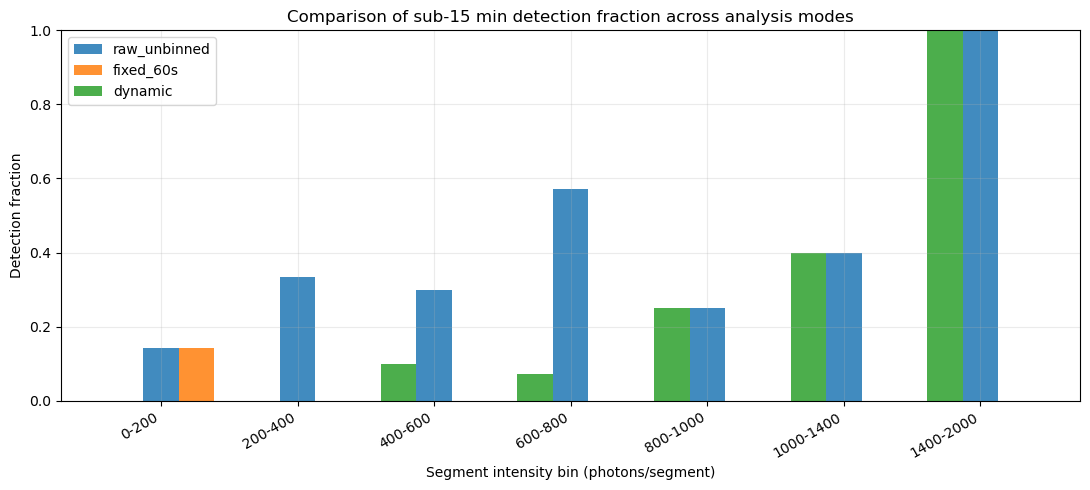

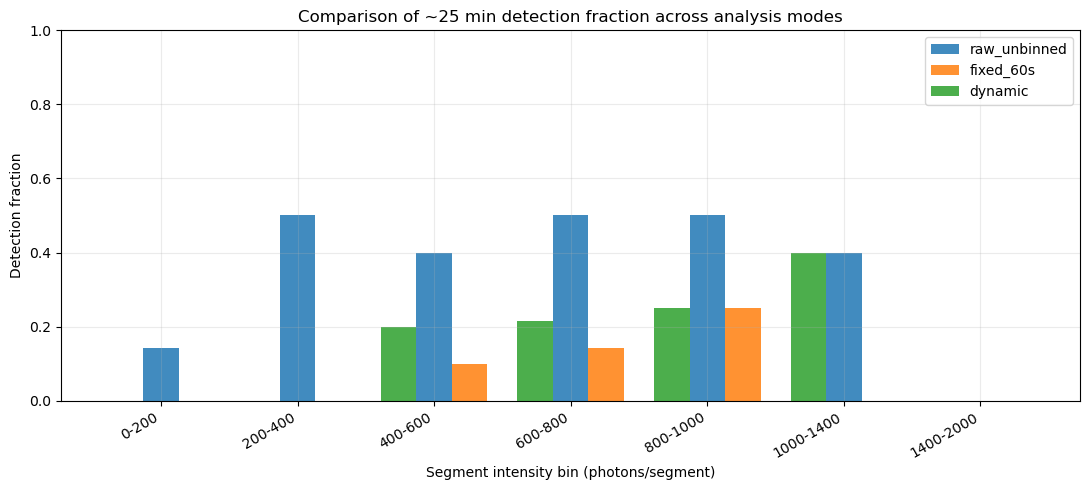

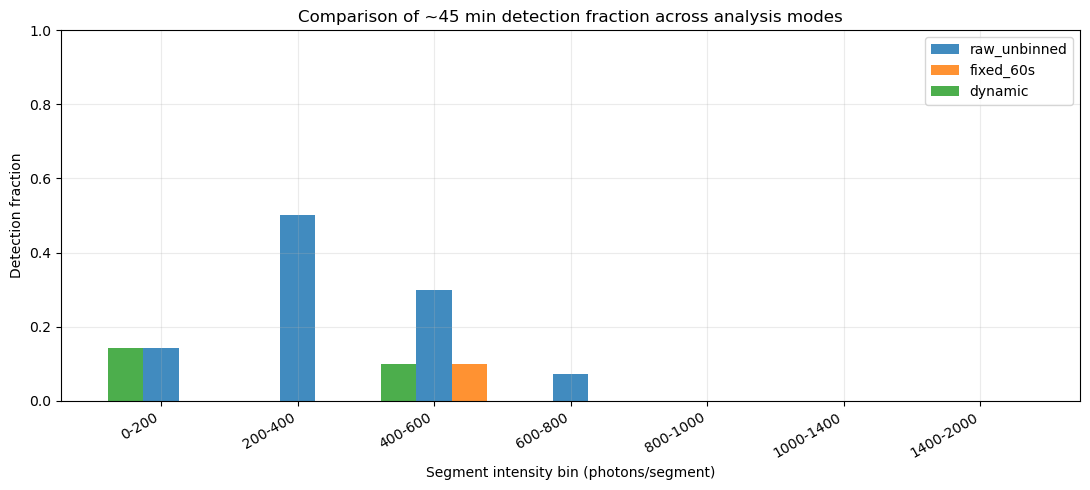

In [38]:
plot_mode_comparison_fractions(results, family="sub15")
plot_mode_comparison_fractions(results, family="p25")
plot_mode_comparison_fractions(results, family="p45")

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typing import Dict, List
from joblib import Parallel, delayed

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = [
    'P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
    'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
    'P0861950201', 'P0882110501', 'P0882110601'
]

data_dir = 'Data_Files/Fenn_Data/'

gap_threshold_s = 3600.0
fixed_bin_size_s = 60.0
base_bin_size = 10

intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]

sub15_window = (2.0, 15.0)
around25_window = (24.0, 26.0)
around45_window = (44.0, 46.0)

search_period_range = (2.0, 90.0)
fap_alpha = 0.10

# Monte Carlo settings for unbinned Rayleigh significance
rayleigh_mc_nsim = 3000
rayleigh_mc_nfreq = 5000
rayleigh_random_seed = 42

# Parallel settings
n_workers = 10
use_parallel = True

# Output
save_segment_table_csv = True
segment_table_csv = "segment_detection_results.csv"


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def split_segments_sorted(obs_id: str, gap_threshold: float = 3600.0):
    _, t_cxc = load_combined_times(obs_id, data_dir)
    t_cxc = np.sort(t_cxc)

    _, gap_idx = find_gaps(t_cxc, threshold=gap_threshold)
    starts = np.r_[0, gap_idx + 1]
    ends = np.r_[gap_idx + 1, len(t_cxc)]

    return [t_cxc[s:e] for s, e in zip(starts, ends)]


# ─── BINNING HELPERS ──────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))

    bins = np.arange(start, end + bin_size, bin_size)
    if len(bins) < 2:
        bins = np.array([start, start + bin_size])

    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 400, high_thresh: float = 800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── PERIOD HELPERS ───────────────────────────────────────────────────────────
def classify_period_window(period_min: float) -> str:
    if np.isnan(period_min):
        return "none"
    if sub15_window[0] <= period_min < sub15_window[1]:
        return "sub15"
    if around25_window[0] <= period_min <= around25_window[1]:
        return "p25"
    if around45_window[0] <= period_min <= around45_window[1]:
        return "p45"
    return "other"


def rayleigh_power(phases_rad: np.ndarray) -> float:
    n = len(phases_rad)
    if n == 0:
        return np.nan
    csum = np.sum(np.cos(phases_rad))
    ssum = np.sum(np.sin(phases_rad))
    return (csum**2 + ssum**2) / n


def rayleigh_periodogram(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    nfreq=5000,
):
    if len(event_times_cxc) < 2:
        return None, None, None, None

    t_min = (event_times_cxc - np.min(event_times_cxc)) / 60.0
    duration_min = np.max(t_min) - np.min(t_min)

    if duration_min <= 0:
        return None, None, None, None

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)
    period_min = 1.0 / freq

    power = np.empty_like(freq)
    for i, f in enumerate(freq):
        phases = 2.0 * np.pi * f * t_min
        power[i] = rayleigh_power(phases)

    return freq, period_min, power, t_min


def monte_carlo_rayleigh_threshold_and_pvalue(
    n_events: int,
    duration_min: float,
    observed_peak_power: float,
    search_period_range=(2.0, 90.0),
    alpha=0.10,
    nfreq=5000,
    nsim=1000,
    rng=None,
):
    if rng is None:
        rng = np.random.default_rng()

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]
    freq = np.linspace(fmin, fmax, nfreq)

    max_powers = np.empty(nsim, dtype=float)

    for i in range(nsim):
        sim_t = np.sort(rng.uniform(0.0, duration_min, size=n_events))

        phases = 2.0 * np.pi * freq[:, None] * sim_t[None, :]
        csum = np.sum(np.cos(phases), axis=1)
        ssum = np.sum(np.sin(phases), axis=1)
        sim_power = (csum**2 + ssum**2) / n_events

        max_powers[i] = np.max(sim_power)

    thresh = np.quantile(max_powers, 1.0 - alpha)
    p_approx = (1.0 + np.sum(max_powers >= observed_peak_power)) / (nsim + 1.0)

    return thresh, p_approx, max_powers


# ─── PER-METHOD DETECTORS ─────────────────────────────────────────────────────
def detect_periods_unbinned_rayleigh_mc(
    event_times_cxc: np.ndarray,
    search_period_range=(2.0, 90.0),
    alpha=0.10,
    nfreq=5000,
    nsim=1000,
    rng=None,
):
    result = {
        "peak_period_min": np.nan,
        "peak_power": np.nan,
        "p_value": np.nan,
        "threshold": np.nan,
        "peak_family": "none",
        "sub15_detect": False,
        "p25_detect": False,
        "p45_detect": False,
    }

    if len(event_times_cxc) < 8:
        return result

    freq, period_min, power, t_min = rayleigh_periodogram(
        event_times_cxc,
        search_period_range=search_period_range,
        nfreq=nfreq,
    )

    if freq is None:
        return result

    duration_min = np.max(t_min) - np.min(t_min)
    if duration_min <= 0:
        return result

    i_peak = int(np.argmax(power))
    peak_period = float(period_min[i_peak])
    peak_power = float(power[i_peak])

    thresh, p_approx, _ = monte_carlo_rayleigh_threshold_and_pvalue(
        n_events=len(event_times_cxc),
        duration_min=duration_min,
        observed_peak_power=peak_power,
        search_period_range=search_period_range,
        alpha=alpha,
        nfreq=nfreq,
        nsim=nsim,
        rng=rng,
    )

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    result["peak_period_min"] = peak_period
    result["peak_power"] = peak_power
    result["p_value"] = p_approx
    result["threshold"] = thresh
    result["peak_family"] = classify_period_window(peak_period)
    result["sub15_detect"] = bool(np.any(power[m_sub] >= thresh)) if np.any(m_sub) else False
    result["p25_detect"] = bool(np.any(power[m_25] >= thresh)) if np.any(m_25) else False
    result["p45_detect"] = bool(np.any(power[m_45] >= thresh)) if np.any(m_45) else False

    return result


def detect_periods_binned_ls(
    centers: np.ndarray,
    counts: np.ndarray,
    search_period_range=(2.0, 90.0),
    alpha=0.10,
):
    result = {
        "peak_period_min": np.nan,
        "peak_power": np.nan,
        "p_value": np.nan,
        "threshold": np.nan,
        "peak_family": "none",
        "sub15_detect": False,
        "p25_detect": False,
        "p45_detect": False,
    }

    if len(centers) < 8 or np.sum(counts) <= 0:
        return result

    t_min = (centers - centers.min()) / 60.0
    y = counts.astype(float) - np.mean(counts)

    if np.allclose(y, 0):
        return result

    ls = LombScargle(t_min, y, fit_mean=False, center_data=True)

    fmin = 1.0 / search_period_range[1]
    fmax = 1.0 / search_period_range[0]

    freq, power = ls.autopower(
        minimum_frequency=fmin,
        maximum_frequency=fmax,
        samples_per_peak=10,
    )
    period_min = 1.0 / freq

    i_peak = int(np.argmax(power))
    peak_period = float(period_min[i_peak])
    peak_power = float(power[i_peak])

    try:
        thresh = float(ls.false_alarm_level(alpha))
    except Exception:
        thresh = np.nan

    try:
        p_value = float(ls.false_alarm_probability(peak_power))
    except Exception:
        p_value = np.nan

    m_sub = (period_min >= sub15_window[0]) & (period_min < sub15_window[1])
    m_25 = (period_min >= around25_window[0]) & (period_min <= around25_window[1])
    m_45 = (period_min >= around45_window[0]) & (period_min <= around45_window[1])

    result["peak_period_min"] = peak_period
    result["peak_power"] = peak_power
    result["p_value"] = p_value
    result["threshold"] = thresh
    result["peak_family"] = classify_period_window(peak_period)
    result["sub15_detect"] = bool(np.any(power[m_sub] >= thresh)) if np.any(m_sub) and np.isfinite(thresh) else False
    result["p25_detect"] = bool(np.any(power[m_25] >= thresh)) if np.any(m_25) and np.isfinite(thresh) else False
    result["p45_detect"] = bool(np.any(power[m_45] >= thresh)) if np.any(m_45) and np.isfinite(thresh) else False

    return result


# ─── SAFE SEGMENT WORKER ──────────────────────────────────────────────────────
def process_single_segment_safe(task):
    obs_id, segment_num, segment_cxc, seed = task

    try:
        rng = np.random.default_rng(seed)
        n_photons = int(len(segment_cxc))

        raw_res = detect_periods_unbinned_rayleigh_mc(
            segment_cxc,
            search_period_range=search_period_range,
            alpha=fap_alpha,
            nfreq=rayleigh_mc_nfreq,
            nsim=rayleigh_mc_nsim,
            rng=rng,
        )

        centers_fixed, counts_fixed = bin_photon_times(segment_cxc, fixed_bin_size_s)
        fixed_res = detect_periods_binned_ls(
            centers_fixed,
            counts_fixed,
            search_period_range=search_period_range,
            alpha=fap_alpha,
        )

        dynamic_bin_s, centers_dyn, counts_dyn, dyn_category = prepare_segment_bins(
            segment_cxc, base_bin_size
        )
        dyn_res = detect_periods_binned_ls(
            centers_dyn,
            counts_dyn,
            search_period_range=search_period_range,
            alpha=fap_alpha,
        )

        return {
            "obs_id": obs_id,
            "segment_num": segment_num,
            "n_photons": n_photons,
            "dynamic_bin_s": dynamic_bin_s,
            "dynamic_category": dyn_category,

            "raw_peak_min": raw_res["peak_period_min"],
            "raw_peak_power": raw_res["peak_power"],
            "raw_p_value": raw_res["p_value"],
            "raw_peak_family": raw_res["peak_family"],
            "raw_sub15_detect": raw_res["sub15_detect"],
            "raw_p25_detect": raw_res["p25_detect"],
            "raw_p45_detect": raw_res["p45_detect"],

            "fixed_peak_min": fixed_res["peak_period_min"],
            "fixed_peak_power": fixed_res["peak_power"],
            "fixed_p_value": fixed_res["p_value"],
            "fixed_peak_family": fixed_res["peak_family"],
            "fixed_sub15_detect": fixed_res["sub15_detect"],
            "fixed_p25_detect": fixed_res["p25_detect"],
            "fixed_p45_detect": fixed_res["p45_detect"],

            "dynamic_peak_min": dyn_res["peak_period_min"],
            "dynamic_peak_power": dyn_res["peak_power"],
            "dynamic_p_value": dyn_res["p_value"],
            "dynamic_peak_family": dyn_res["peak_family"],
            "dynamic_sub15_detect": dyn_res["sub15_detect"],
            "dynamic_p25_detect": dyn_res["p25_detect"],
            "dynamic_p45_detect": dyn_res["p45_detect"],

            "status": "ok",
            "error": "",
        }

    except Exception as e:
        return {
            "obs_id": obs_id,
            "segment_num": segment_num,
            "n_photons": len(segment_cxc) if segment_cxc is not None else np.nan,
            "dynamic_bin_s": np.nan,
            "dynamic_category": "",
            "raw_peak_min": np.nan,
            "raw_peak_power": np.nan,
            "raw_p_value": np.nan,
            "raw_peak_family": "none",
            "raw_sub15_detect": False,
            "raw_p25_detect": False,
            "raw_p45_detect": False,
            "fixed_peak_min": np.nan,
            "fixed_peak_power": np.nan,
            "fixed_p_value": np.nan,
            "fixed_peak_family": "none",
            "fixed_sub15_detect": False,
            "fixed_p25_detect": False,
            "fixed_p45_detect": False,
            "dynamic_peak_min": np.nan,
            "dynamic_peak_power": np.nan,
            "dynamic_p_value": np.nan,
            "dynamic_peak_family": "none",
            "dynamic_sub15_detect": False,
            "dynamic_p25_detect": False,
            "dynamic_p45_detect": False,
            "status": "error",
            "error": f"{type(e).__name__}: {e}",
        }


# ─── BUILD TASKS ──────────────────────────────────────────────────────────────
def build_segment_tasks(obs_ids: List[str], gap_threshold: float, base_seed: int = 42):
    tasks = []
    seed_seq = np.random.SeedSequence(base_seed)

    all_segments = []
    for obs in obs_ids:
        segs = split_segments_sorted(obs, gap_threshold=gap_threshold)
        print(f"Loaded {obs}: {len(segs)} segments")
        for i, seg in enumerate(segs, start=1):
            seg = np.asarray(seg, dtype=float)
            all_segments.append((obs, i, seg))

    child_seeds = seed_seq.spawn(len(all_segments))

    for (obs, i, seg), s in zip(all_segments, child_seeds):
        seed_int = int(s.generate_state(1)[0])
        tasks.append((obs, i, seg, seed_int))

    return tasks


# ─── SERIAL / PARALLEL RUNNERS ────────────────────────────────────────────────
def run_segment_analysis_serial(
    obs_ids: List[str],
    gap_threshold: float = 3600.0,
    base_seed: int = 42,
):
    tasks = build_segment_tasks(obs_ids, gap_threshold=gap_threshold, base_seed=base_seed)

    rows = []
    for k, task in enumerate(tasks, start=1):
        rows.append(process_single_segment_safe(task))
        if (k % 10 == 0) or (k == len(tasks)):
            print(f"Completed {k}/{len(tasks)} segments")

    df = pd.DataFrame(rows)
    df = df.sort_values(["obs_id", "segment_num"]).reset_index(drop=True)
    return df


def run_parallel_segment_analysis(
    obs_ids: List[str],
    gap_threshold: float = 3600.0,
    n_workers: int = 4,
    base_seed: int = 42,
    use_parallel: bool = True,
):
    tasks = build_segment_tasks(obs_ids, gap_threshold=gap_threshold, base_seed=base_seed)

    if not use_parallel or n_workers <= 1:
        print("Running in serial mode")
        rows = [process_single_segment_safe(task) for task in tasks]
        df = pd.DataFrame(rows)
        return df.sort_values(["obs_id", "segment_num"]).reset_index(drop=True)

    try:
        print(f"Running in parallel with joblib/loky using {n_workers} workers")

        rows = Parallel(
            n_jobs=n_workers,
            backend="loky",
            verbose=10,
        )(
            delayed(process_single_segment_safe)(task)
            for task in tasks
        )

        df = pd.DataFrame(rows)
        return df.sort_values(["obs_id", "segment_num"]).reset_index(drop=True)

    except Exception as e:
        print("\nParallel execution failed, falling back to serial mode.")
        print(f"Reason: {type(e).__name__}: {e}")
        return run_segment_analysis_serial(
            obs_ids=obs_ids,
            gap_threshold=gap_threshold,
            base_seed=base_seed,
        )


# ─── SUMMARY BY INTENSITY BIN ─────────────────────────────────────────────────
def summarise_method_by_intensity_bins(
    df: pd.DataFrame,
    method_prefix: str,
    intensity_bin_edges: List[float],
):
    edges = np.asarray(intensity_bin_edges, dtype=float)
    if np.any(np.diff(edges) <= 0):
        raise ValueError("intensity_bin_edges must be strictly increasing.")

    nphot = df["n_photons"].to_numpy()
    sub15 = df[f"{method_prefix}_sub15_detect"].to_numpy(dtype=bool)
    p25 = df[f"{method_prefix}_p25_detect"].to_numpy(dtype=bool)
    p45 = df[f"{method_prefix}_p45_detect"].to_numpy(dtype=bool)

    bin_idx = np.digitize(nphot, edges, right=False) - 1
    valid = (bin_idx >= 0) & (bin_idx < len(edges) - 1)

    labels = []
    n_seg, n_sub, n_25, n_45 = [], [], [], []
    sub_frac, p25_frac, p45_frac = [], [], []
    sub_frac_err, p25_frac_err, p45_frac_err = [], [], []
    ratio, ratio_err = [], []

    for i_bin in range(len(edges) - 1):
        m = valid & (bin_idx == i_bin)

        ns = int(np.sum(m))
        s = int(np.sum(sub15[m]))
        p = int(np.sum(p25[m]))
        q = int(np.sum(p45[m]))

        labels.append(f"{int(edges[i_bin])}-{int(edges[i_bin+1])}")
        n_seg.append(ns)
        n_sub.append(s)
        n_25.append(p)
        n_45.append(q)

        if ns > 0:
            fs = s / ns
            fp = p / ns
            fq = q / ns

            es = np.sqrt(fs * (1 - fs) / ns)
            ep = np.sqrt(fp * (1 - fp) / ns)
            eq = np.sqrt(fq * (1 - fq) / ns)
        else:
            fs = fp = fq = np.nan
            es = ep = eq = np.nan

        sub_frac.append(fs)
        p25_frac.append(fp)
        p45_frac.append(fq)

        sub_frac_err.append(es)
        p25_frac_err.append(ep)
        p45_frac_err.append(eq)

        if q > 0 and s > 0:
            r = s / q
            re = r * np.sqrt((1 / s) + (1 / q))
        elif q > 0 and s == 0:
            r = 0.0
            re = np.nan
        else:
            r = np.nan
            re = np.nan

        ratio.append(r)
        ratio_err.append(re)

    return {
        "mode": method_prefix,
        "labels": labels,
        "n_seg": np.array(n_seg),
        "n_sub": np.array(n_sub),
        "n_25": np.array(n_25),
        "n_45": np.array(n_45),
        "sub_frac": np.array(sub_frac, dtype=float),
        "p25_frac": np.array(p25_frac, dtype=float),
        "p45_frac": np.array(p45_frac, dtype=float),
        "sub_frac_err": np.array(sub_frac_err, dtype=float),
        "p25_frac_err": np.array(p25_frac_err, dtype=float),
        "p45_frac_err": np.array(p45_frac_err, dtype=float),
        "ratio": np.array(ratio, dtype=float),
        "ratio_err": np.array(ratio_err, dtype=float),
    }


def print_summary_table(summary: Dict):
    print(f"\n=== {summary['mode']} ===")
    print("Intensity bin | N seg | sub<15 det | ~25 det | ~45 det | sub<15 frac | ~25 frac | ~45 frac | ratio(sub15/~45)")
    for i in range(len(summary["labels"])):
        print(
            f"{summary['labels'][i]:>11} | "
            f"{summary['n_seg'][i]:5d} | "
            f"{summary['n_sub'][i]:10d} | "
            f"{summary['n_25'][i]:7d} | "
            f"{summary['n_45'][i]:7d} | "
            f"{summary['sub_frac'][i]:10.3f} | "
            f"{summary['p25_frac'][i]:8.3f} | "
            f"{summary['p45_frac'][i]:8.3f} | "
            f"{summary['ratio'][i]:14.3f}"
        )


# ─── MAIN RUNNER ──────────────────────────────────────────────────────────────
def main():
    df_segments = run_parallel_segment_analysis(
        obs_ids=ident,
        gap_threshold=gap_threshold_s,
        n_workers=n_workers,
        base_seed=rayleigh_random_seed,
        use_parallel=use_parallel,
    )

    cols_to_show = [
        "obs_id", "segment_num", "n_photons",
        "raw_peak_min", "raw_p_value", "raw_peak_family",
        "fixed_peak_min", "fixed_p_value", "fixed_peak_family",
        "dynamic_peak_min", "dynamic_p_value", "dynamic_peak_family",
        "status", "error",
    ]

    print("\nPer-segment results:")
    print(df_segments[cols_to_show].to_string(index=False))

    if save_segment_table_csv:
        df_segments.to_csv(segment_table_csv, index=False)
        print(f"\nSaved segment table to: {segment_table_csv}")

    df_ok = df_segments[df_segments["status"] == "ok"].copy()

    results = {
        "raw": summarise_method_by_intensity_bins(df_ok, "raw", intensity_bin_edges),
        "fixed": summarise_method_by_intensity_bins(df_ok, "fixed", intensity_bin_edges),
        "dynamic": summarise_method_by_intensity_bins(df_ok, "dynamic", intensity_bin_edges),
    }

    print_summary_table(results["raw"])
    print_summary_table(results["fixed"])
    print_summary_table(results["dynamic"])

    return df_segments, results


df_segments, results = main()

Loaded P0781830301: 2 segments
Loaded P0781830601: 2 segments
Loaded P0801930701: 4 segments
Loaded P0801930801: 5 segments
Loaded P0801930901: 3 segments
Loaded P0801931901: 3 segments
Loaded P0842810501: 4 segments
Loaded P0842811001: 4 segments
Loaded P0842811501: 4 segments
Loaded P0842812001: 4 segments
Loaded P0861950201: 4 segments
Loaded P0882110501: 3 segments
Loaded P0882110601: 5 segments
Running in parallel with joblib/loky using 10 workers


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   5 tasks      | elapsed:   48.8s
[Parallel(n_jobs=10)]: Done  12 tasks      | elapsed:  3.1min
[Parallel(n_jobs=10)]: Done  21 tasks      | elapsed:  4.7min
[Parallel(n_jobs=10)]: Done  33 out of  47 | elapsed:  6.8min remaining:  2.9min
[Parallel(n_jobs=10)]: Done  38 out of  47 | elapsed:  7.7min remaining:  1.8min
[Parallel(n_jobs=10)]: Done  43 out of  47 | elapsed:  8.9min remaining:   49.7s



Per-segment results:
     obs_id  segment_num  n_photons  raw_peak_min  raw_p_value raw_peak_family  fixed_peak_min  fixed_p_value fixed_peak_family  dynamic_peak_min  dynamic_p_value dynamic_peak_family status error
P0781830301            1        328     34.357388     0.022326           other       18.425638       0.967791             other         18.410788     9.365679e-01               other     ok      
P0781830301            2        769     20.927020     0.001000           other       20.656827       0.084994             other         20.673881     9.653746e-03               other     ok      
P0781830601            1        252      2.392642     0.972676           sub15       66.059113       0.886825             other         66.098361     9.070934e-01               other     ok      
P0781830601            2        868      8.495440     0.124292           sub15        8.489036       0.622474             sub15          8.486497     7.683131e-02               sub15     ok     

[Parallel(n_jobs=10)]: Done  47 out of  47 | elapsed: 11.0min finished


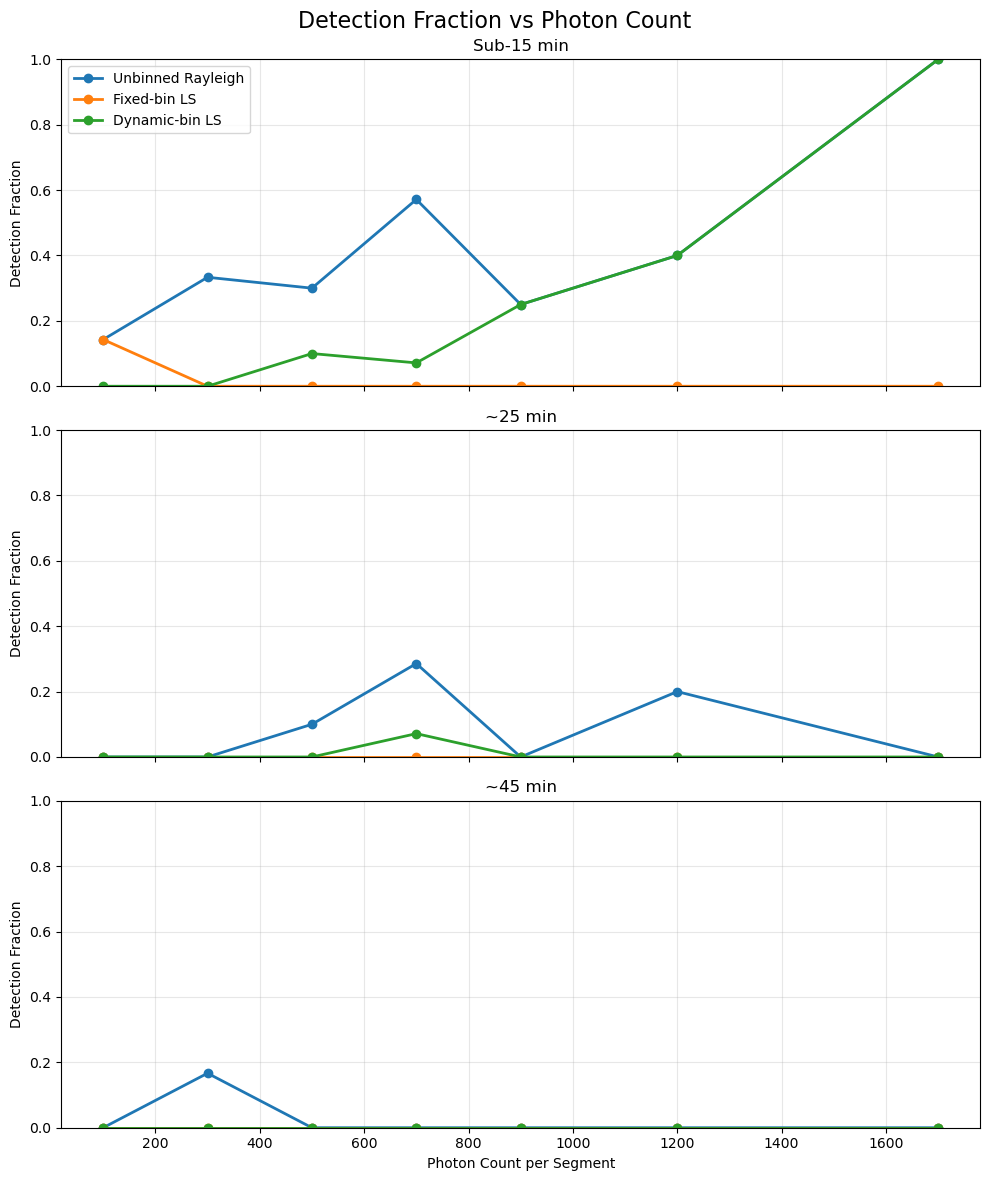

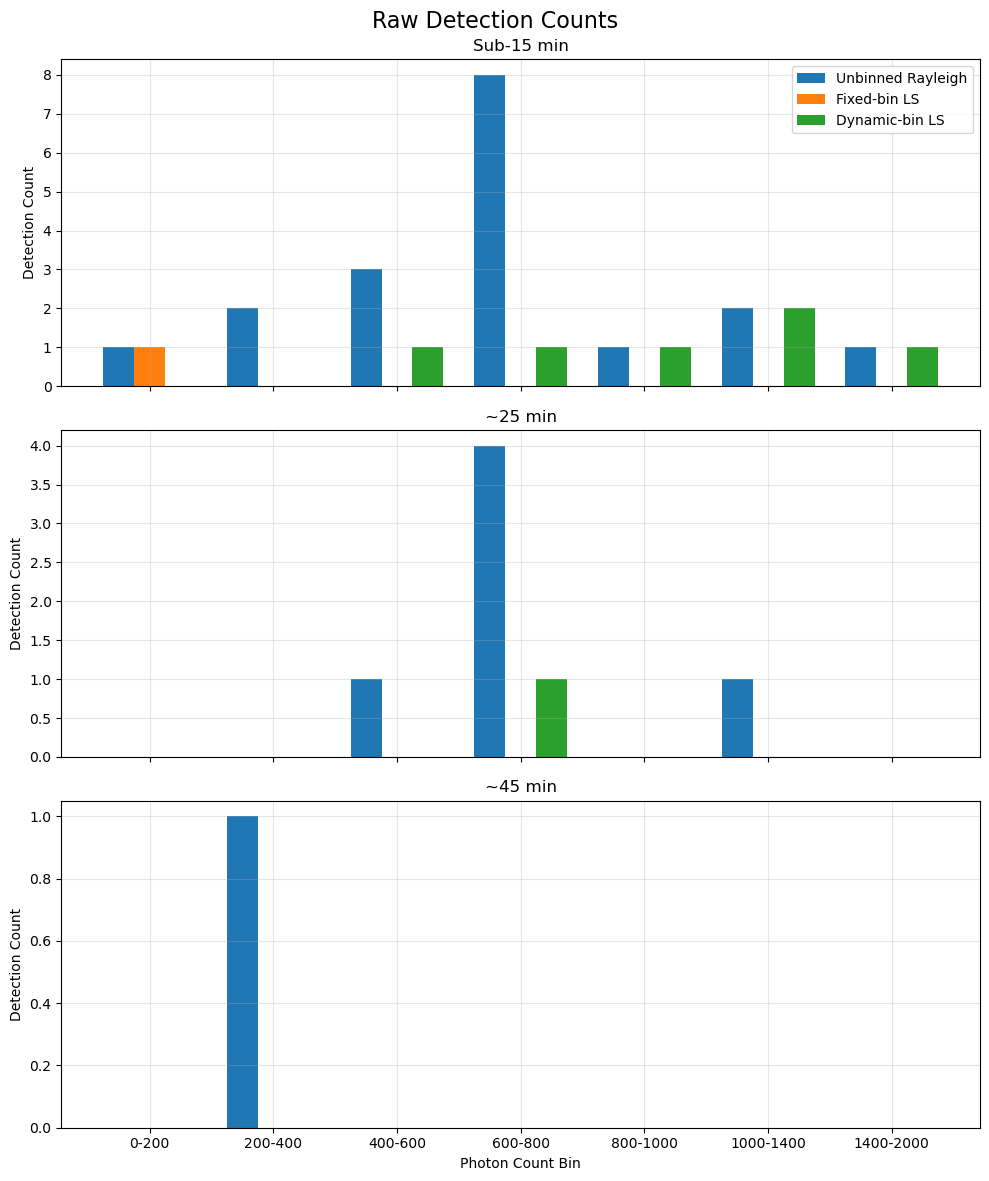

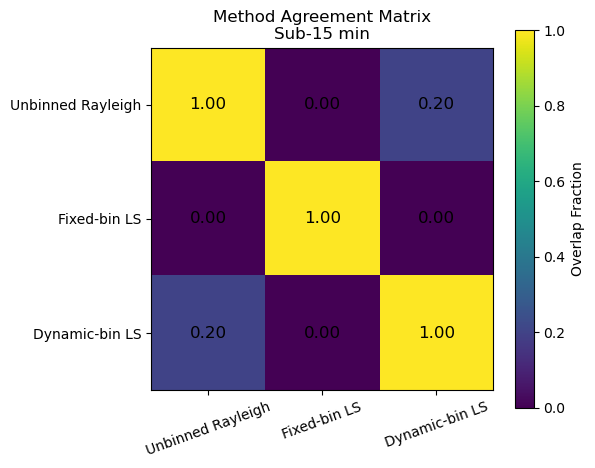

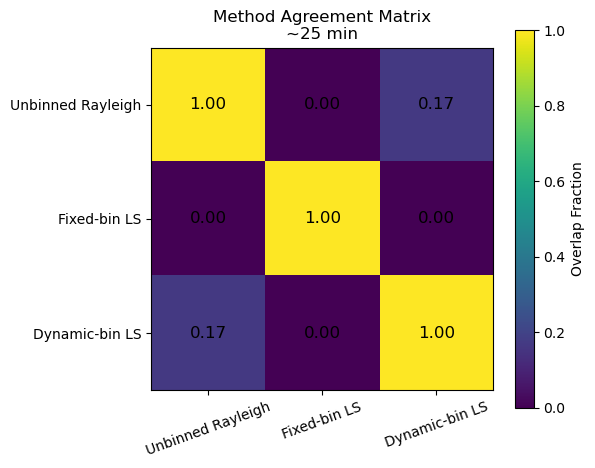

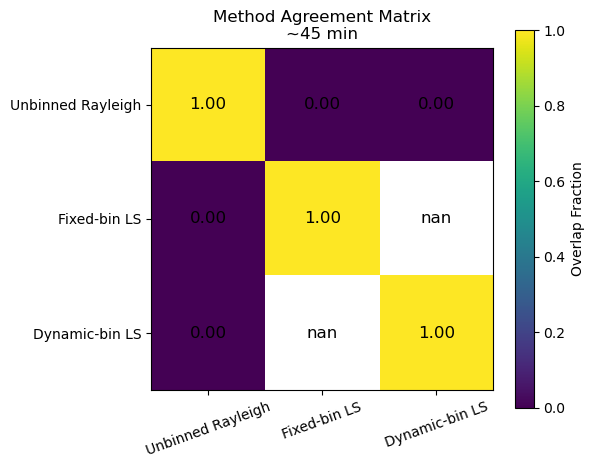

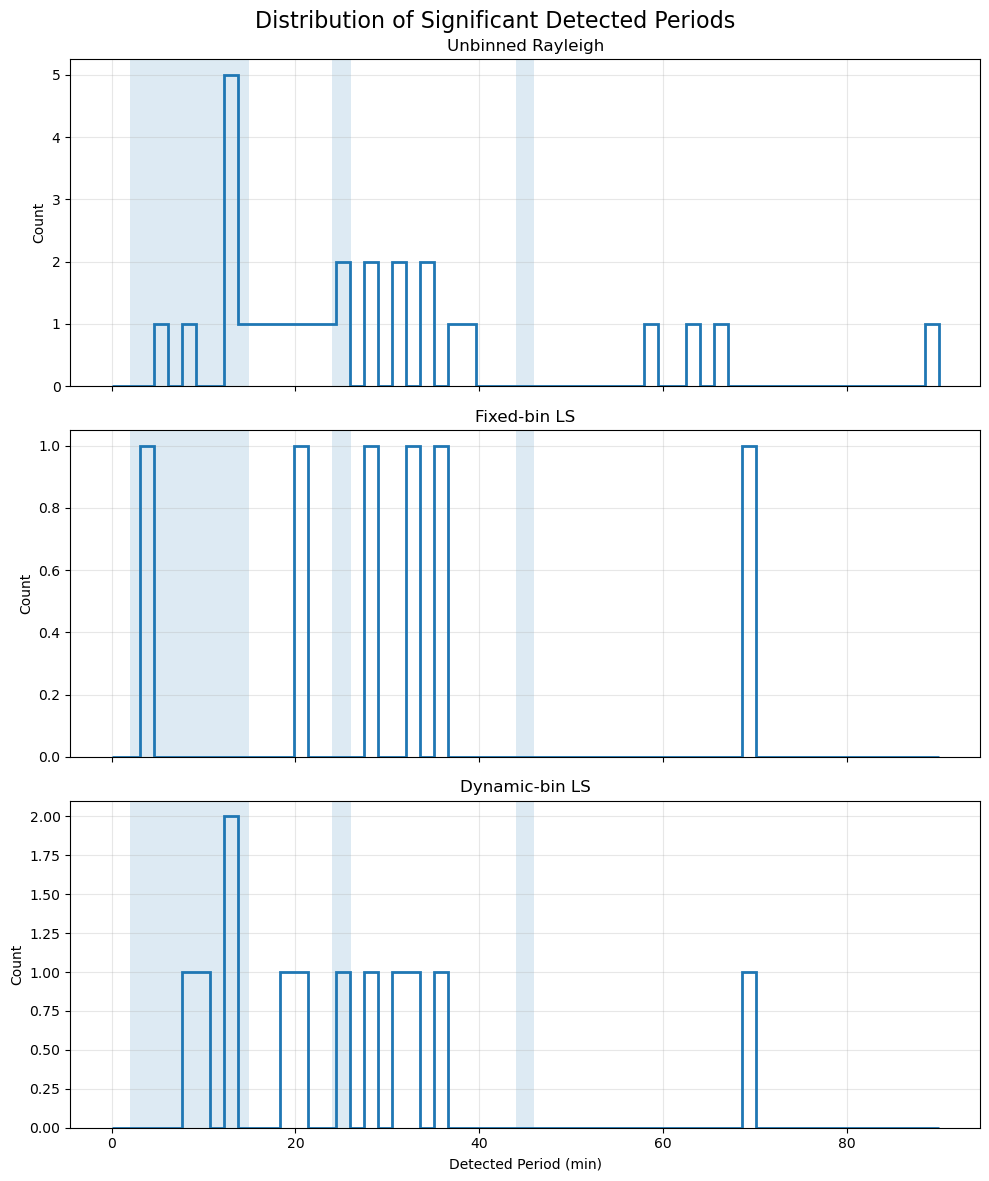

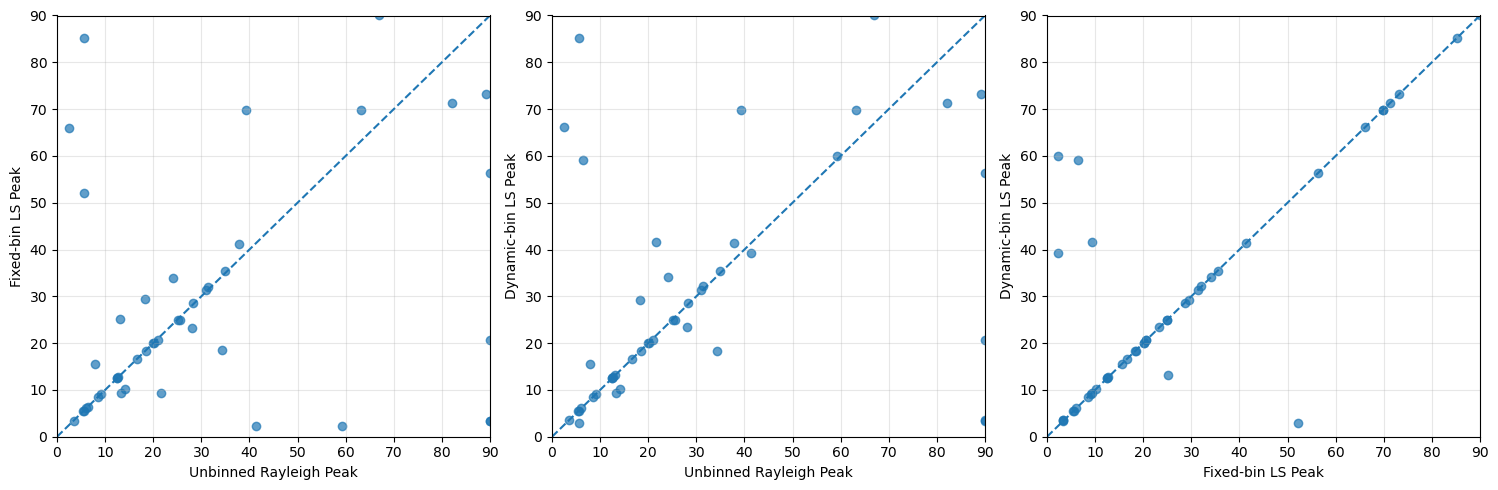


GLOBAL DETECTION FRACTIONS

Unbinned Rayleigh
   sub15 :   18 /   47 (0.383)
     p25 :    6 /   47 (0.128)
     p45 :    1 /   47 (0.021)

Fixed-bin LS
   sub15 :    1 /   47 (0.021)
     p25 :    0 /   47 (0.000)
     p45 :    0 /   47 (0.000)

Dynamic-bin LS
   sub15 :    6 /   47 (0.128)
     p25 :    1 /   47 (0.021)
     p45 :    0 /   47 (0.000)

Finished.


In [5]:
# =============================================================================
# PLOT ESSENTIAL FIGURES FROM SEGMENT DETECTION ANALYSIS
# =============================================================================
#
# This script assumes you have already run:
#
#     df_segments, results = main()
#
# OR have saved:
#
#     segment_detection_results.csv
#
# It produces:
#
# 1. Detection fraction vs photon count
# 2. Raw detection counts vs photon count
# 3. Method agreement matrices
# 4. Period distribution histograms
# 5. Example method comparison diagnostics
#
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations


# =============================================================================
# USER SETTINGS
# =============================================================================

LOAD_FROM_CSV = True
CSV_FILE = "segment_detection_results.csv"

SAVE_FIGURES = True
FIG_DIR = "essential_figures"

methods = ["raw", "fixed", "dynamic"]

method_labels = {
    "raw": "Unbinned Rayleigh",
    "fixed": "Fixed-bin LS",
    "dynamic": "Dynamic-bin LS",
}

period_families = {
    "sub15": "Sub-15 min",
    "p25": "~25 min",
    "p45": "~45 min",
}

intensity_bin_edges = [0, 200, 400, 600, 800, 1000, 1400, 2000]


# =============================================================================
# LOAD DATA
# =============================================================================

if LOAD_FROM_CSV:
    df = pd.read_csv(CSV_FILE)
else:
    df = df_segments.copy()

df = df[df["status"] == "ok"].copy()

if SAVE_FIGURES:
    import os
    os.makedirs(FIG_DIR, exist_ok=True)


# =============================================================================
# BINNING UTILITIES
# =============================================================================

def compute_detection_stats(df, method, family, edges):

    detect_col = f"{method}_{family}_detect"

    labels = []
    centers = []

    n_seg = []
    n_det = []

    frac = []
    frac_err = []

    for i in range(len(edges) - 1):

        lo = edges[i]
        hi = edges[i + 1]

        m = (df["n_photons"] >= lo) & (df["n_photons"] < hi)

        ns = np.sum(m)
        nd = np.sum(df.loc[m, detect_col])

        labels.append(f"{lo}-{hi}")
        centers.append(0.5 * (lo + hi))

        n_seg.append(ns)
        n_det.append(nd)

        if ns > 0:
            f = nd / ns
            e = np.sqrt(f * (1 - f) / ns)
        else:
            f = np.nan
            e = np.nan

        frac.append(f)
        frac_err.append(e)

    return {
        "labels": labels,
        "centers": np.array(centers),
        "n_seg": np.array(n_seg),
        "n_det": np.array(n_det),
        "frac": np.array(frac),
        "frac_err": np.array(frac_err),
    }


# =============================================================================
# FIGURE 1
# DETECTION FRACTION VS PHOTON COUNT
# =============================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 12),
    sharex=True,
)

for ax, family in zip(axes, ["sub15", "p25", "p45"]):

    for method in methods:

        stats = compute_detection_stats(
            df,
            method,
            family,
            intensity_bin_edges,
        )

        ax.plot(
            stats["centers"],
            stats["frac"],
            marker="o",
            linewidth=2,
            label=method_labels[method],
        )

    ax.set_ylabel("Detection Fraction")
    ax.set_ylim(0, 1)

    ax.set_title(period_families[family])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Photon Count per Segment")

axes[0].legend()

fig.suptitle(
    "Detection Fraction vs Photon Count",
    fontsize=16,
)

plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        f"{FIG_DIR}/detection_fraction_vs_photon_count.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# =============================================================================
# FIGURE 2
# RAW DETECTION COUNTS
# =============================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 12),
    sharex=True,
)

x = np.arange(len(intensity_bin_edges) - 1)

width = 0.25

for ax, family in zip(axes, ["sub15", "p25", "p45"]):

    for i, method in enumerate(methods):

        stats = compute_detection_stats(
            df,
            method,
            family,
            intensity_bin_edges,
        )

        ax.bar(
            x + i * width,
            stats["n_det"],
            width=width,
            label=method_labels[method],
        )

    ax.set_ylabel("Detection Count")
    ax.set_title(period_families[family])

    ax.set_xticks(x + width)
    ax.set_xticklabels(stats["labels"])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Photon Count Bin")

axes[0].legend()

fig.suptitle(
    "Raw Detection Counts",
    fontsize=16,
)

plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        f"{FIG_DIR}/raw_detection_counts.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# =============================================================================
# FIGURE 3
# METHOD AGREEMENT MATRICES
# =============================================================================

def method_overlap_fraction(df, method1, method2, family):

    c1 = df[f"{method1}_{family}_detect"].astype(bool)
    c2 = df[f"{method2}_{family}_detect"].astype(bool)

    union = np.sum(c1 | c2)

    if union == 0:
        return np.nan

    inter = np.sum(c1 & c2)

    return inter / union


for family in ["sub15", "p25", "p45"]:

    matrix = np.zeros((3, 3))

    for i, m1 in enumerate(methods):
        for j, m2 in enumerate(methods):

            if i == j:
                matrix[i, j] = 1.0
            else:
                matrix[i, j] = method_overlap_fraction(
                    df,
                    m1,
                    m2,
                    family,
                )

    fig, ax = plt.subplots(figsize=(6, 5))

    im = ax.imshow(matrix, vmin=0, vmax=1)

    ax.set_xticks(np.arange(3))
    ax.set_yticks(np.arange(3))

    ax.set_xticklabels([method_labels[m] for m in methods], rotation=20)
    ax.set_yticklabels([method_labels[m] for m in methods])

    for i in range(3):
        for j in range(3):
            ax.text(
                j,
                i,
                f"{matrix[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=12,
            )

    ax.set_title(
        f"Method Agreement Matrix\n{period_families[family]}"
    )

    plt.colorbar(im, ax=ax, label="Overlap Fraction")

    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            f"{FIG_DIR}/agreement_matrix_{family}.png",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()


# =============================================================================
# FIGURE 4
# DETECTED PERIOD DISTRIBUTIONS
# =============================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 12),
    sharex=True,
)

bins = np.linspace(0, 90, 60)

for ax, method in zip(axes, methods):

    peak_col = f"{method}_peak_min"
    p_col = f"{method}_p_value"

    good = (
        np.isfinite(df[peak_col]) &
        np.isfinite(df[p_col]) &
        (df[p_col] < 0.10)
    )

    ax.hist(
        df.loc[good, peak_col],
        bins=bins,
        histtype="step",
        linewidth=2,
    )

    ax.axvspan(2, 15, alpha=0.15)
    ax.axvspan(24, 26, alpha=0.15)
    ax.axvspan(44, 46, alpha=0.15)

    ax.set_ylabel("Count")

    ax.set_title(method_labels[method])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Detected Period (min)")

fig.suptitle(
    "Distribution of Significant Detected Periods",
    fontsize=16,
)

plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        f"{FIG_DIR}/period_distributions.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# =============================================================================
# FIGURE 5
# METHOD COMPARISON SCATTER
# =============================================================================

pairs = [
    ("raw", "fixed"),
    ("raw", "dynamic"),
    ("fixed", "dynamic"),
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
)

for ax, (m1, m2) in zip(axes, pairs):

    p1 = df[f"{m1}_peak_min"]
    p2 = df[f"{m2}_peak_min"]

    good = np.isfinite(p1) & np.isfinite(p2)

    ax.scatter(
        p1[good],
        p2[good],
        alpha=0.7,
    )

    ax.plot([0, 90], [0, 90], linestyle="--")

    ax.set_xlim(0, 90)
    ax.set_ylim(0, 90)

    ax.set_xlabel(f"{method_labels[m1]} Peak")
    ax.set_ylabel(f"{method_labels[m2]} Peak")

    ax.grid(alpha=0.3)

plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        f"{FIG_DIR}/method_peak_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# =============================================================================
# OPTIONAL QUICK SUMMARY TABLE
# =============================================================================

print("\n========================================================")
print("GLOBAL DETECTION FRACTIONS")
print("========================================================")

for method in methods:

    print(f"\n{method_labels[method]}")

    for family in ["sub15", "p25", "p45"]:

        detect_col = f"{method}_{family}_detect"

        ndet = np.sum(df[detect_col])
        ntot = len(df)

        frac = ndet / ntot

        print(
            f"{family:>8} : "
            f"{ndet:4d} / {ntot:4d} "
            f"({frac:.3f})"
        )


print("\nFinished.")


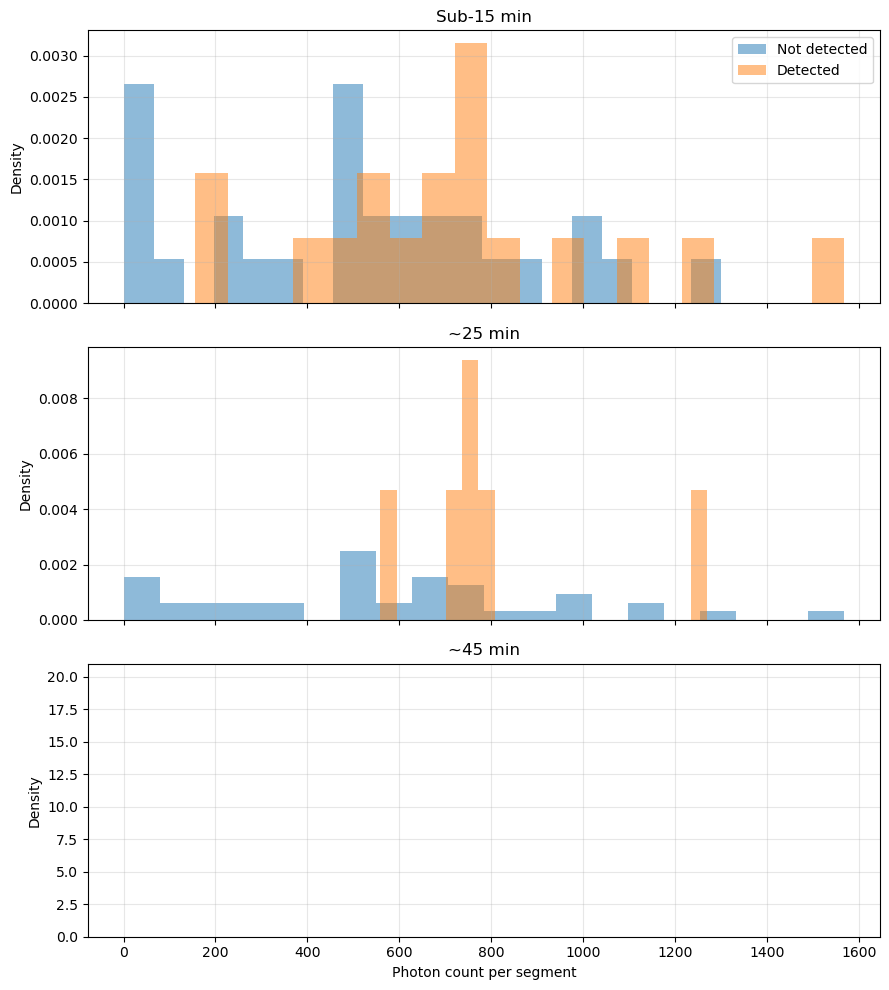

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)

families = ["sub15", "p25", "p45"]

for ax, family in zip(axes, families):
    detect_col = f"raw_{family}_detect"

    detected = df.loc[df[detect_col].astype(bool), "n_photons"]
    not_detected = df.loc[~df[detect_col].astype(bool), "n_photons"]

    ax.hist(
        not_detected,
        bins=20,
        alpha=0.5,
        label="Not detected",
        density=True,
    )

    ax.hist(
        detected,
        bins=20,
        alpha=0.5,
        label="Detected",
        density=True,
    )

    ax.set_ylabel("Density")
    ax.set_title(period_families[family])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Photon count per segment")
axes[0].legend()

plt.tight_layout()
plt.show()


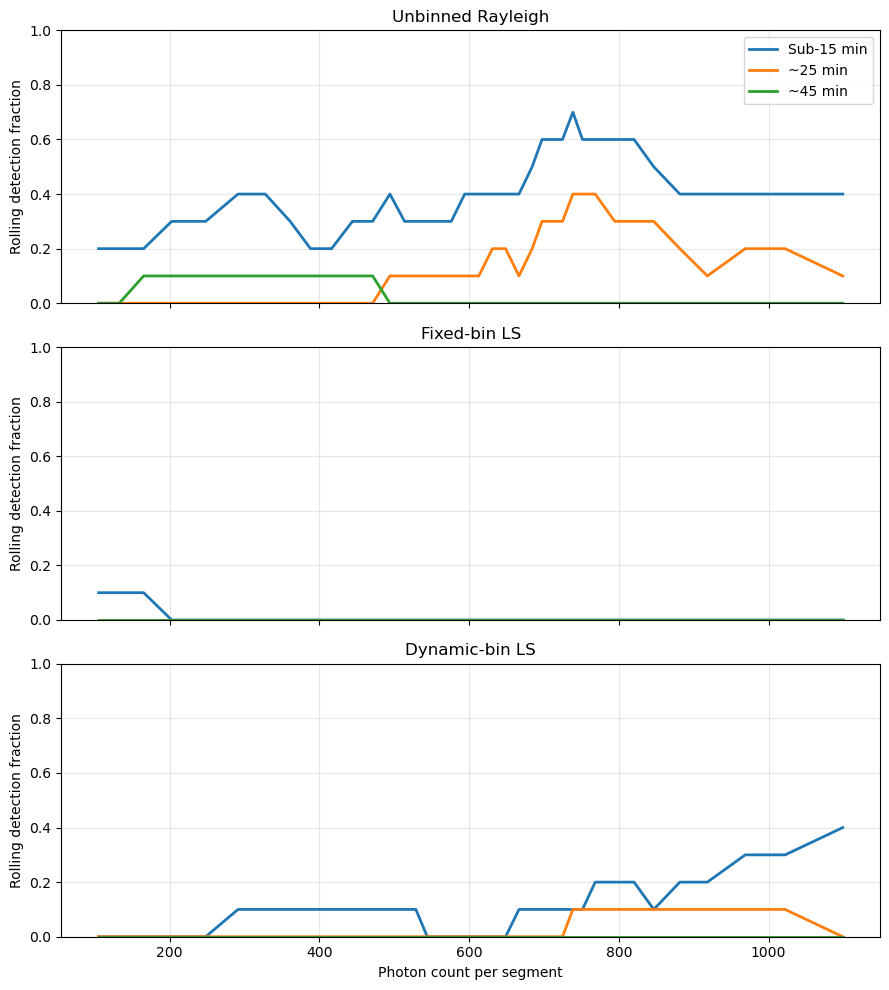

In [7]:
def rolling_detection_fraction(df, detect_col, window=10):
    d = df[["n_photons", detect_col]].copy()
    d = d.sort_values("n_photons").reset_index(drop=True)

    x = d["n_photons"].rolling(window, center=True).mean()
    y = d[detect_col].astype(float).rolling(window, center=True).mean()

    return x, y


fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)

for ax, method in zip(axes, methods):

    for family in ["sub15", "p25", "p45"]:
        detect_col = f"{method}_{family}_detect"

        x, y = rolling_detection_fraction(
            df,
            detect_col,
            window=10,
        )

        ax.plot(
            x,
            y,
            linewidth=2,
            label=period_families[family],
        )

    ax.set_ylabel("Rolling detection fraction")
    ax.set_title(method_labels[method])
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Photon count per segment")
axes[0].legend()

plt.tight_layout()
plt.show()

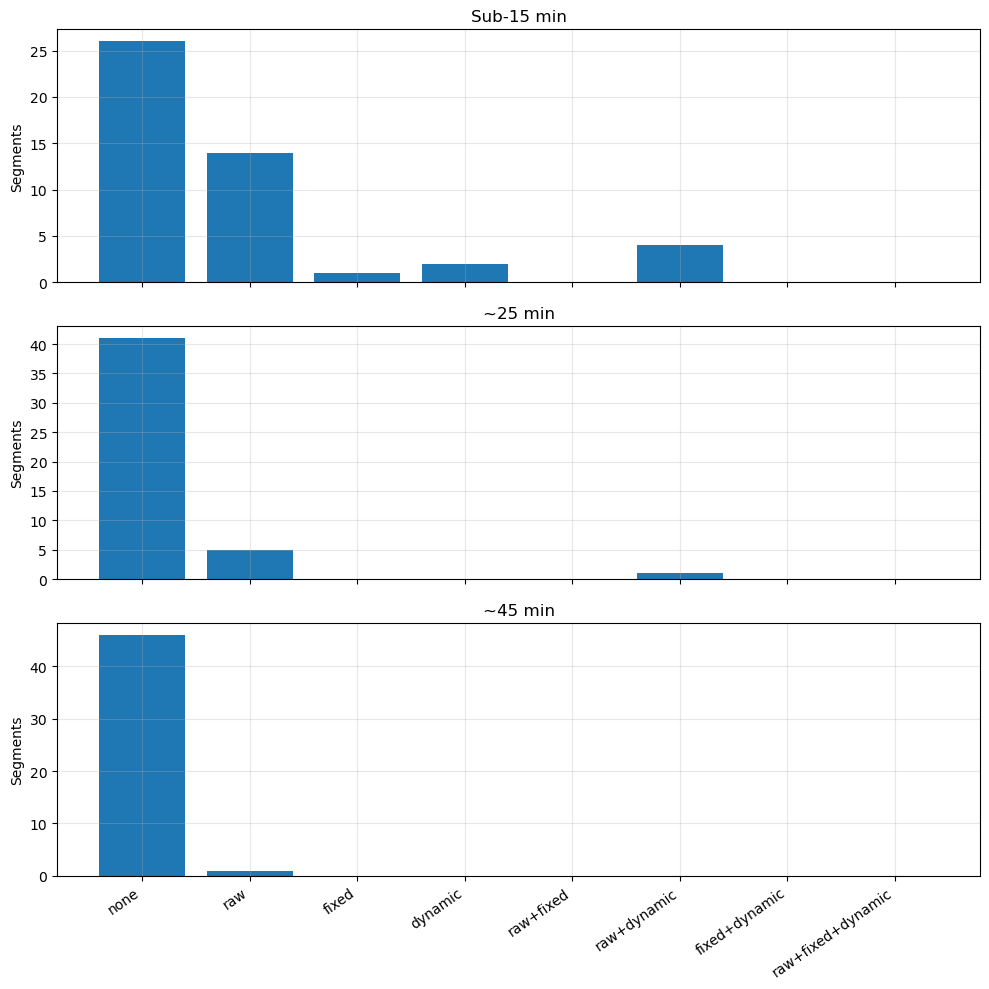

In [8]:
def detection_pattern(row, family):
    flags = []

    for method in methods:
        if bool(row[f"{method}_{family}_detect"]):
            flags.append(method)

    if len(flags) == 0:
        return "none"

    return "+".join(flags)


pattern_order = [
    "none",
    "raw",
    "fixed",
    "dynamic",
    "raw+fixed",
    "raw+dynamic",
    "fixed+dynamic",
    "raw+fixed+dynamic",
]

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

for ax, family in zip(axes, ["sub15", "p25", "p45"]):

    patterns = df.apply(
        lambda row: detection_pattern(row, family),
        axis=1,
    )

    counts = patterns.value_counts().reindex(pattern_order, fill_value=0)

    ax.bar(
        np.arange(len(pattern_order)),
        counts.values,
    )

    ax.set_ylabel("Segments")
    ax.set_title(period_families[family])
    ax.grid(alpha=0.3)

axes[-1].set_xticks(np.arange(len(pattern_order)))
axes[-1].set_xticklabels(pattern_order, rotation=35, ha="right")

plt.tight_layout()
plt.show()